
# FJD B 端割草机器人 · Meta Lead Ads 投放数据分析

**数据周期：** 2026-05-01 至 2026-07-17（连续 11 个自然周）
**投放平台：** Meta（Facebook / Instagram）Lead Generation 广告
**分析对象：** B 端（Business）割草机器人相关产品的广告花费、点击与线索（Lead）表现

## 项目背景与分析目标

本项目基于 FJD 割草机器人 B 端 Meta Lead Ads 连续 11 周的周度投放报表，复盘广告花费（Spend）、展示（Impressions）、链接点击（Link Clicks）与潜在客户线索（Leads）的规模与效率，并从国家/地区、广告系列（Campaign）与产品型号三个维度拆解表现。

分析目标：

1. 建立**统一、可复现**的数据清洗与指标口径，避免同一份数据在不同模块里使用不同规则；
2. 评估整体与周度投放趋势，识别放量/收缩与获客成本的变化；
3. 比较国家/地区与 Campaign 的获客效率，指出值得优先关注和需要谨慎对待的方向；
4. 从产品型号 x 国家交叉视角，观察哪类产品在哪些市场更具效率；
5. 以**初步诊断框架**的形式输出优化优先级，并明确其中的假设与局限。

> 说明：本 Notebook 的所有观察均基于报表的实际运行结果。凡缺少销售跟进、线索质量、Demo、成交或收入数据支撑的判断，一律作为**待验证的假设**，不作为确定性的业务结论。



## 一、数据来源、字段说明与数据质量检查

### 1.1 分析目的

在进入具体分析之前，先确认数据来源、字段含义与数据质量，避免在错误口径上继续计算。

### 1.2 数据来源

项目目录下共有两类 Excel 文件：

| 文件 | 说明 |
| --- | --- |
| `5.1-5.8.xlsx` … `7.10-7.17.xlsx`（共 11 个） | Meta 导出的**周度原始报表**，每份对应一个报告周期，结构一致 |
| `To B meta ads analysis.xlsx` | 由上述周报合并得到的汇总文件 |

为保证可复现性，本 Notebook **直接从 11 份周度原始报表合并**，并在质量检查环节验证合并结果与汇总文件一致。

### 1.3 字段说明

| 字段 | 含义 | 本项目中的用途 |
| --- | --- | --- |
| `来源文件` | 记录该行来自哪份周报（合并时新增） | 追溯数据来源 |
| `国家/地区` | 广告投放的国家/地区代码 | 国家维度分析 |
| `广告系列名称` | Campaign 名称，内含产品型号与投放变体 | Campaign 与产品型号分析 |
| `已花费金额 (USD)` | 广告花费（美元） | Spend、CPL、CPC、CPM |
| `展示次数` | 广告展示次数 | 分母指标 |
| `链接点击量` | 链接点击量（Link Clicks） | Link CTR、Click-to-Lead |
| `成效` | Meta 记录的潜在客户（Lead）数量 | Leads |
| `覆盖人数` | 该报告周期内的**去重覆盖人数**（分周统计） | 仅做口径说明，不跨周求和 |
| `频次` | 该报告周期内的**平均展示频次**（分周统计） | 仅做口径说明，不跨周求和 |
| `点击率（全部）` | Meta 自带的“全部点击”点击率 | 仅作对照，本项目统一使用 Link CTR |
| `单次链接点击费用` / `单次成效费用` | Meta 自带的单次费用字段 | 仅作对照，本项目统一按聚合口径重算 |
| `CPM（千次展示费用）` | Meta 自带千次展示费用 | 仅作对照，本项目统一按聚合口径重算 |
| `报告开始日期` / `报告结束日期` | 报告周期 | 周度趋势的时间轴 |
| `成效类型` / `结果（初始）` | 成效类型标签 / 空字段 | 本项目不使用 |

### 1.4 关键指标口径（全文统一）

设某分组内的总花费为 `Spend`，展示为 `Impressions`，链接点击为 `Link Clicks`，线索为 `Leads`，则：

- `CPL = Spend / Leads`
- `Link CTR = Link Clicks / Impressions`
- `Click-to-Lead Rate = Leads / Link Clicks`
- `CPC = Spend / Link Clicks`
- `CPM = Spend / Impressions x 1000`
- `Lead Share = 该分组 Leads / 全部 Leads`

> 所有比率指标均基于**聚合后的总量**重新计算，而不是对逐行的比率取平均，避免小样本记录被过度放大。


In [1]:

# =========================================================
# 1. 环境与全局配置
# =========================================================
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# 统一图表风格。图表标签使用英文，避免运行环境缺少中文字体时出现乱码。
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "figure.figsize": (10, 6),
    "font.size": 11,
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
})

# 统一配色
C_SPEND, C_LEADS, C_CPL = "#3b6ea5", "#4c9a6a", "#c0504d"
C_RATE, C_WARN, C_NEUT = "#8a6fb0", "#d98a3c", "#6b7280"

# ---- 分析参数（集中定义，便于后续调整；含义与局限见第八节）----
TARGET_CPL        = 10.0   # 示例目标 CPL（USD），并非行业标准
MIN_LEADS         = 10     # 排名/决策的最低线索门槛
MIN_LEADS_HIGH    = 20     # 判定“已具备一定规模”的门槛
LOW_LINK_CTR      = 0.008  # 启发式：偏低链接点击率
HIGH_CPC          = 1.50   # 启发式：偏高单次点击成本（USD）
LOW_CLICK_TO_LEAD = 0.05   # 启发式：偏低点击→线索转化率


def fmt_money(v):
    return f"${v:,.2f}" if pd.notna(v) else "-"

def fmt_int(v):
    return f"{int(v):,}" if pd.notna(v) else "-"

def fmt_pct(v):
    return f"{v:.2%}" if pd.notna(v) else "-"

def show(obj):
    """统一展示入口：在 Jupyter 中渲染表格 / 对象。"""
    display(obj)

print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", plt.matplotlib.__version__)


pandas 3.0.6 | numpy 2.5.3 | matplotlib 3.11.2



### 1.5 读取原始周报

读取目录下的 11 份周报并纵向合并；合并时新增 `来源文件` 列，便于后续追溯每一行数据的出处。


In [2]:

# =========================================================
# 1.5 读取并合并原始周报
# =========================================================
raw_files = sorted(f for f in glob.glob("*.xlsx") if not f.startswith("To B"))

frames = []
for f in raw_files:
    part = pd.read_excel(f)
    part.columns = part.columns.str.strip()
    part.insert(0, "来源文件", f)
    frames.append(part)

raw = pd.concat(frames, ignore_index=True)

print("周报文件数量：", len(raw_files))
print("周报文件：", raw_files)
print("合并后数据规模（行, 列）：", raw.shape)

show(raw.head())


周报文件数量： 11
周报文件： ['5.1-5.8.xlsx', '5.15-5.22.xlsx', '5.22-5.29.xlsx', '5.29-6.5.xlsx', '5.8-5.15.xlsx', '6.12-6.19.xlsx', '6.19-6.26.xlsx', '6.26-7.3.xlsx', '6.5-6.12.xlsx', '7.10-7.17.xlsx', '7.3-7.10.xlsx']
合并后数据规模（行, 列）： (469, 17)


,来源文件,国家/地区,广告系列名称,已花费金额 (USD),单次链接点击费用,CPM（千次展示费用）,点击率（全部）,成效类型,成效,单次成效费用,展示次数,链接点击量,覆盖人数,频次,报告开始日期,报告结束日期,结果（初始）
0,5.1-5.8.xlsx,NZ,Leads_New_FJD_RLM01_FJD BU (Robotic Lawn Mower 1）_20260126,27.67,0.709487,6.202645,1.882986,潜在客户信息（表单）量,7.0,3.952857,4461,39.0,2979,1.497482,2026-05-01,2026-05-08,-
1,5.1-5.8.xlsx,US,Leads_New_FJD_RCM01_FJD BU (Robotic Lawn Mower 4）_20260402,74.29,0.844205,29.363636,5.849802,潜在客户信息（表单）量,13.0,5.714615,2530,88.0,2036,1.242633,2026-05-01,2026-05-08,-
2,5.1-5.8.xlsx,NL,Leads_New_FJD_RCM01_FJD BU (Robotic Lawn Mower 2）_20260402,11.25,0.661765,25.167785,7.606264,潜在客户信息（表单）量,1.0,11.250000,447,17.0,324,1.379630,2026-05-01,2026-05-08,-
3,5.1-5.8.xlsx,BE,Leads_New_FJD_RCM01_FJD BU (Robotic Lawn Mower 2）_20260402,39.53,1.040263,15.489812,3.565831,潜在客户信息（表单）量,4.0,9.882500,2552,38.0,1865,1.368365,2026-05-01,2026-05-08,-
4,5.1-5.8.xlsx,GB,Leads_New_FJD_FRX_FJD BU (Robotic Lawn Mower 1）_20260126,40.10,1.293548,27.827897,3.678001,潜在客户信息（表单）量,6.0,6.683333,1441,31.0,1214,1.186985,2026-05-01,2026-05-08,-



## 二、数据质量检查

### 2.1 分析目的

先报告数据中存在的问题，再决定是否处理，避免"看到异常就删"。本节检查：

1. 数值/日期字段的类型是否正确；
2. 缺失值、重复记录；
3. 花费为 0、`unknown` 国家/地区、负值等异常；
4. 报告周期是否重叠、是否存在缺失的周；
5. 合并结果是否与汇总文件一致。

### 2.2 关键口径

- 原始字段中，空值与"真实为 0"需要区分：`成效` 为空表示该记录未产生 Lead，应按 0 处理；但需要先统计数量再处理。
- 报告周期以 `报告开始日期` / `报告结束日期` 为准，用于判断重叠与缺周。


In [3]:

# =========================================================
# 2. 数据质量检查
# =========================================================
print("=" * 60)
print("2.1 字段类型")
print("=" * 60)
show(pd.DataFrame({"dtype": raw.dtypes.astype(str)}))

print("\n" + "=" * 60)
print("2.2 缺失值")
print("=" * 60)
missing = raw.isnull().sum()
show(pd.DataFrame({"缺失数量": missing[missing > 0], "缺失占比": (missing / len(raw))[missing > 0].map(lambda v: f"{v:.1%}")}))

print("\n" + "=" * 60)
print("2.3 重复记录")
print("=" * 60)
dup_all = raw.duplicated().sum()
dup_key = raw.duplicated(subset=["来源文件", "国家/地区", "广告系列名称", "报告开始日期"]).sum()
print("完全重复的行数：", dup_all)
print("按 来源文件 + 国家 + Campaign + 报告开始日期 判定的重复行数：", dup_key)

print("\n" + "=" * 60)
print("2.4 异常值 / 边界情况")
print("=" * 60)
num_cols = ["已花费金额 (USD)", "成效", "展示次数", "链接点击量", "覆盖人数", "频次"]
num_checked = raw[num_cols].apply(pd.to_numeric, errors="coerce")
neg = {c: int((num_checked[c] < 0).sum()) for c in num_cols}
print("各数值字段负值数量：", neg)
print("花费为 0 的记录数：", int((num_checked["已花费金额 (USD)"] == 0).sum()))
print("花费为 0 但有 Lead 的记录数：", int(((num_checked["已花费金额 (USD)"] == 0) & (num_checked["成效"] > 0)).sum()))
unknown_mask = raw["国家/地区"].astype(str).str.strip().str.lower().eq("unknown")
print("国家/地区 = unknown 的记录数：", int(unknown_mask.sum()))
print("unknown 记录合计花费（USD）：", round(num_checked.loc[unknown_mask, "已花费金额 (USD)"].sum(), 4))

print("\n" + "=" * 60)
print("2.5 报告周期检查")
print("=" * 60)
periods = (raw.assign(
        _start=pd.to_datetime(raw["报告开始日期"]),
        _end=pd.to_datetime(raw["报告结束日期"]))
    .groupby("来源文件")
    .agg(报告开始=("_start", "min"), 报告结束=("_end", "max"), 天数=("_start", lambda s: (s.max() - s.min()).days),
         记录数=("来源文件", "size"))
    .sort_index())
show(periods)

starts = sorted(pd.to_datetime(raw["报告开始日期"]).dt.normalize().unique())
ends = sorted(pd.to_datetime(raw["报告结束日期"]).dt.normalize().unique())
print("\n报告开始日期集合：", [pd.Timestamp(s).strftime("%Y-%m-%d") for s in starts])
print("报告结束日期集合：", [pd.Timestamp(e).strftime("%Y-%m-%d") for e in ends])
overlap = set(pd.Timestamp(s) for s in starts) & set(pd.Timestamp(e) for e in ends)
print("同时出现在“开始日期”和“结束日期”中的日期：", [d.strftime("%Y-%m-%d") for d in sorted(overlap)])
week_starts = pd.to_datetime(raw["报告开始日期"]).dt.normalize().unique()
gaps = pd.date_range(min(week_starts), max(week_starts), freq="7D")
print("按 7 天步长应有周数：", len(gaps), "，实际周数：", len(week_starts))

print("\n" + "=" * 60)
print("2.6 与汇总文件一致性校验")
print("=" * 60)
merged = pd.read_excel("To B meta ads analysis.xlsx")
merged.columns = merged.columns.str.strip()
print("周报合并行数：", len(raw), "| 汇总文件行数：", len(merged))
match = all(
    np.isclose(pd.to_numeric(raw[c], errors="coerce").sum(),
               pd.to_numeric(merged[c], errors="coerce").sum())
    for c in ["已花费金额 (USD)", "展示次数", "链接点击量", "成效"]
)
print("关键指标合计一致：", match)


2.1 字段类型

2.2 缺失值

2.3 重复记录
完全重复的行数： 0
按 来源文件 + 国家 + Campaign + 报告开始日期 判定的重复行数： 0

2.4 异常值 / 边界情况
各数值字段负值数量： {'已花费金额 (USD)': 0, '成效': 0, '展示次数': 0, '链接点击量': 0, '覆盖人数': 0, '频次': 0}
花费为 0 的记录数： 1
花费为 0 但有 Lead 的记录数： 1
国家/地区 = unknown 的记录数： 3
unknown 记录合计花费（USD）： 0.05

2.5 报告周期检查

报告开始日期集合： ['2026-05-01', '2026-05-08', '2026-05-15', '2026-05-22', '2026-05-29', '2026-06-05', '2026-06-12', '2026-06-19', '2026-06-26', '2026-07-03', '2026-07-10']
报告结束日期集合： ['2026-05-08', '2026-05-15', '2026-05-22', '2026-05-29', '2026-06-05', '2026-06-12', '2026-06-19', '2026-06-26', '2026-07-03', '2026-07-10', '2026-07-17']
同时出现在“开始日期”和“结束日期”中的日期： ['2026-05-08', '2026-05-15', '2026-05-22', '2026-05-29', '2026-06-05', '2026-06-12', '2026-06-19', '2026-06-26', '2026-07-03', '2026-07-10']
按 7 天步长应有周数： 11 ，实际周数： 11

2.6 与汇总文件一致性校验
周报合并行数： 469 | 汇总文件行数： 469
关键指标合计一致： True


,dtype
来源文件,str
国家/地区,str
广告系列名称,str
已花费金额 (USD),float64
单次链接点击费用,float64
CPM（千次展示费用）,float64
点击率（全部）,float64
成效类型,str
成效,float64
单次成效费用,float64


,缺失数量,缺失占比
单次链接点击费用,12,2.6%
CPM（千次展示费用）,1,0.2%
点击率（全部）,1,0.2%
成效类型,113,24.1%
成效,113,24.1%
单次成效费用,113,24.1%
链接点击量,12,2.6%
结果（初始）,469,100.0%


,报告开始,报告结束,天数,记录数
来源文件,,,,
5.1-5.8.xlsx,2026-05-01,2026-05-08,0,51
5.15-5.22.xlsx,2026-05-15,2026-05-22,0,66
5.22-5.29.xlsx,2026-05-22,2026-05-29,0,66
5.29-6.5.xlsx,2026-05-29,2026-06-05,0,74
5.8-5.15.xlsx,2026-05-08,2026-05-15,0,69
6.12-6.19.xlsx,2026-06-12,2026-06-19,0,35
6.19-6.26.xlsx,2026-06-19,2026-06-26,0,21
6.26-7.3.xlsx,2026-06-26,2026-07-03,0,14
6.5-6.12.xlsx,2026-06-05,2026-06-12,0,45



### 2.3 数据质量检查发现

根据上述代码的实际输出：

1. **字段类型：** 周报中日期字段以文本形式导出，数值字段本身形态正常；在清洗阶段会统一转换类型。
2. **缺失值：** 主要出现在 `成效`、`成效类型`、`单次成效费用`（均为 113 条）以及 `链接点击量`、`单次链接点击费用`（均为 12 条）。其中 `成效` 为空代表该记录**未产生 Lead**，按 0 处理，不删除整行。
3. **重复记录：** 完全重复行数为 0；按"来源文件 + 国家 + Campaign + 报告开始日期"判定的重复行数同样为 0，说明每条记录在报表内的唯一性可以保证。
4. **异常值：**
   - 花费为 0 的记录有 1 条，且该记录带有 1 个 Lead（花费、展示、点击为 0 却产生线索），属于口径异常，保留但单独标注。该行会让整体 CPL 被极轻微低估（1 个无成本 Lead / 总计 2,661 个 Lead，影响 < 0.04%），不影响整体结论。
   - `国家/地区 = unknown` 的记录有 3 条，合计花费不足 0.1 USD、展示 3 次，量级可忽略，保留但单独标注，不并入正常国家。
   - 各数值字段均无负值。
5. **报告周期：** 11 份周报的报告周期连续、无缺口，周数为 11（起始 2026-05-01，结束 2026-07-17）。相邻周报的"结束日期"与下一份的"开始日期"是同一天，共出现 **10 个共享边界日期**（05-08、05-15 …… 07-10）。
   - **重复累计风险：** 若 Meta 的"报告结束日期"是端点包含，则边界当天会被相邻两周各统计一次，从而在周度相加时重复累计花费/点击/Leads；
   - 本项目无法仅凭报表确认 Meta 的端点取数规则（多数周报为左闭右开 [开始, 结束)），因此**不擅自删除任何数据**，只把该风险明确标注；
   - 由于每份周报差值为 7 天，本项目以"每周报一行、按周独立统计"的方式处理，并在核对环节确认整体 = 各周之和 = 各国之和 = 各 Campaign 之和（见 8.x 核对）。
6. **一致性：** 由 11 份周报合并得到的 Spend / Impressions / Link Clicks / Leads 合计，与汇总文件完全一致，说明本项目直接从原始周报合并的结果是可靠的。

> 结论：数据不存在需要删除整行的问题。花费为 0、`unknown` 等记录将被保留并标注，在后续分析中量级极小，不影响整体结论。



## 三、数据清洗与指标定义

### 3.1 分析目的

在副本 DataFrame 上完成清洗与特征构造，保证后续所有模块使用**同一个**分析数据集，避免"前面用 `df_analysis`、后面又用原始 `df`"导致口径不一致。

### 3.2 清洗规则

| 问题 | 处理方式 | 说明 |
| --- | --- | --- |
| 列名前后空格 | `str.strip()` | 避免同名列被拆成两列 |
| 数值字段类型 | `pd.to_numeric(errors="coerce")` | Spend / Clicks / Impressions / Reach / Frequency |
| `成效` 为空 | 填 0 | 空值代表未产生 Lead，不是缺失 |
| `链接点击量` 为空 | 填 0 | 无点击即 0 |
| 日期字段 | `pd.to_datetime(errors="coerce")` | 统一为日期类型 |
| 花费为 0 / `unknown` | 保留并标注 | 不直接删除 |
| 无穷值 | 转为缺失 | 避免除零结果污染计算 |

### 3.3 派生字段

- `week_start`：报告开始日期（日期类型），用于周度聚合与排序；
- `product_model`：从 Campaign 名称提取的产品型号（见 3.4）；
- `link_ctr`、`click_to_lead_rate`：逐行构造的比率（用于数据检查，聚合分析时重新按总量计算）。


In [4]:

# =========================================================
# 3. 数据清洗
# =========================================================
df_analysis = raw.copy()

# 1) 列名去空格
df_analysis.columns = df_analysis.columns.str.strip()

# 2) 数值字段统一转数值
numeric_cols = ["已花费金额 (USD)", "单次链接点击费用", "CPM（千次展示费用）",
                "点击率（全部）", "成效", "单次成效费用", "展示次数",
                "链接点击量", "覆盖人数", "频次"]
for c in numeric_cols:
    df_analysis[c] = pd.to_numeric(df_analysis[c], errors="coerce")

# 3) 无穷值 -> 缺失
df_analysis = df_analysis.replace([np.inf, -np.inf], np.nan)

# 4) 成效 / 链接点击量的缺失按 0 处理（空 = 未产生）
df_analysis["成效"] = df_analysis["成效"].fillna(0)
df_analysis["链接点击量"] = df_analysis["链接点击量"].fillna(0)

# 5) 日期字段转日期类型
df_analysis["报告开始日期"] = pd.to_datetime(df_analysis["报告开始日期"], errors="coerce")
df_analysis["报告结束日期"] = pd.to_datetime(df_analysis["报告结束日期"], errors="coerce")

# 6) 周标签 = 报告开始日期（保留日期类型，排序不依赖字符串）
df_analysis["week_start"] = df_analysis["报告开始日期"].dt.normalize()

# 7) 标注量级极小的异常记录，便于后续查看（不删除）
df_analysis["is_zero_spend"] = df_analysis["已花费金额 (USD)"].eq(0)
df_analysis["is_unknown_country"] = df_analysis["国家/地区"].astype(str).str.strip().str.lower().eq("unknown")

print("清洗后数据规模：", df_analysis.shape)
print("数值字段缺失（清洗后）：")
show(df_analysis[numeric_cols].isnull().sum().to_frame("缺失数量"))
print("日期范围：", df_analysis["报告开始日期"].min().date(), "->", df_analysis["报告结束日期"].max().date())
print("是否还有日期解析失败：", int(df_analysis["报告开始日期"].isna().sum()))


清洗后数据规模： (469, 20)
数值字段缺失（清洗后）：
日期范围： 2026-05-01 -> 2026-07-17
是否还有日期解析失败： 0


,缺失数量
已花费金额 (USD),0
单次链接点击费用,12
CPM（千次展示费用）,1
点击率（全部）,1
成效,0
单次成效费用,113
展示次数,0
链接点击量,0
覆盖人数,0
频次,0



### 3.4 统一产品型号提取

**统一规则：** 全部产品/交叉分析都调用同一个函数 `extract_product_model()`，且该函数**只依据 Campaign 名称中的产品型号字段**判断。

观察真实 Campaign 命名结构，例如：

```
Leads_New_FJD_RCM01_FJD BU (Robotic Lawn Mower 4）_20260402
Leads_New_FJD_RM21_（全球）_20241231
Leads_New_FJD_高尔夫应用场景_FJD BU（Robotic Lawn Mower 3）_20260104
```

可按 `Leads_New_FJD_` 之后、第一个下划线之前的片段提取型号，得到 `RCM01` / `RM21` / `FRX` / `FR4000` / `RLM01` / `RLM02` / `高尔夫应用场景`。

需要特别说明的两点：

1. 括号中的 `Robotic Lawn Mower 1 / 2 / 3 / 4 / 6 / 7` 只是**同一型号下的素材/受众变体编号**，不是型号。例如 `RLM01 ... (Robotic Lawn Mower 6)` 仍然属于 **RLM01**，不能因为出现 "Robotic Lawn Mower 6" 就归为 "RLM06"。
2. 真实数据中并不存在 `RLM03`、`RLM06` 这两个型号；`高尔夫应用场景` 是应用场景，不是机器人型号，单独归为 `Golf`。

因此：型号可识别时返回标准型号；`高尔夫应用场景` 返回 `Golf`；其余无法可靠识别的记为 `Other/Unknown`。

为避免"命名异常就静默生成一个新型号"，函数内部维护一份**已知型号白名单**，只有命中白名单的型号才会被保留，否则统一归为 `Other/Unknown`。复核时已确认当前 34 个 Campaign 的型号字段全部落在白名单内。


In [5]:

# =========================================================
# 3.4 统一产品型号提取（唯一入口）
# =========================================================
KNOWN_MODELS = {"FR4000", "FRX", "RCM01", "RLM01", "RLM02", "RM21"}

def extract_product_model(campaign_name):
    """从 Campaign 名称解析产品型号（全文唯一入口）。

    规则：取 `Leads_New_FJD_` 之后、第一个下划线之前的片段作为型号字段。
    - 真实型号（白名单）：FR4000 / FRX / RCM01 / RLM01 / RLM02 / RM21
    - 应用场景：高尔夫应用场景 -> Golf
    - 未命中白名单或无法识别 -> Other/Unknown
    括号中的 "Robotic Lawn Mower N" 是变体编号，不参与型号判定。
    """
    m = re.match(r"^Leads_New_FJD_(.+?)_", str(campaign_name))
    token = m.group(1).strip() if m else None
    if not token:
        return "Other/Unknown"
    if token == "高尔夫应用场景":
        return "Golf"
    return token if token in KNOWN_MODELS else "Other/Unknown"


df_analysis["product_model"] = df_analysis["广告系列名称"].apply(extract_product_model)

# 逐行比率（仅用于检查，聚合分析会按总量重算）
df_analysis["link_ctr"] = np.where(
    df_analysis["展示次数"] > 0, df_analysis["链接点击量"] / df_analysis["展示次数"], np.nan)
df_analysis["click_to_lead_rate"] = np.where(
    df_analysis["链接点击量"] > 0, df_analysis["成效"] / df_analysis["链接点击量"], np.nan)

# ---- 校验 0：白名单外出现的型号字段（应为空）----
def _raw_token(campaign_name):
    m = re.match(r"^Leads_New_FJD_(.+?)_", str(campaign_name))
    return m.group(1).strip() if m else None

parsed_tokens = df_analysis["广告系列名称"].map(_raw_token)
unknown_tokens = sorted(set(t for t in parsed_tokens.dropna() if t not in KNOWN_MODELS and t != "高尔夫应用场景"))
print("未命中白名单的型号字段：", unknown_tokens if unknown_tokens else "无")

# ---- 校验 1：型号分布 ----
model_dist = (df_analysis["product_model"].value_counts(dropna=False)
              .rename_axis("product_model").reset_index(name="记录数"))
print("产品型号分布：")
show(model_dist)

# ---- 校验 2：无法识别（Other/Unknown）的记录与对应 Campaign ----
unmatched = df_analysis[df_analysis["product_model"] == "Other/Unknown"]
print("\nOther/Unknown 记录数：", len(unmatched))
if len(unmatched) > 0:
    show(unmatched.groupby("广告系列名称").agg(
        记录数=("广告系列名称", "size"),
        Spend=("已花费金额 (USD)", "sum"),
        Leads=("成效", "sum")).sort_values("Spend", ascending=False))

# ---- 校验 3：每条 Campaign 只匹配一个型号 ----
campaign_models = df_analysis.groupby("广告系列名称")["product_model"].nunique()
print("\n一个 Campaign 对应多个型号的情况：", int((campaign_models > 1).sum()), "条")
print("Campaign 数量：", df_analysis["广告系列名称"].nunique(),
      "| 型号数量：", df_analysis["product_model"].nunique())

# ---- 对照：旧规则的常见误判（仅演示，不参与后续分析）----
def _old_rule(name):
    n = str(name).upper()
    if "FR4000" in n: return "FR4000"
    if "RLM01" in n: return "RLM01"
    if "RLM02" in n: return "RLM02"
    if "RLM03" in n: return "RLM03"
    if "RLM06" in n: return "RLM06"
    if "RCM01" in n: return "RCM01"
    if "RM21" in n: return "RM21"
    if "FRX" in n: return "FRX"
    if "ROBOTIC LAWN MOWER 6" in n: return "RLM06"
    if "ROBOTIC LAWN MOWER 3" in n: return "RLM03"
    if "ROBOTIC LAWN MOWER 1" in n: return "RLM01"
    if "ROBOTIC LAWN MOWER" in n: return "RLM"
    return np.nan

old = df_analysis["广告系列名称"].apply(_old_rule)
changed = df_analysis.loc[old != df_analysis["product_model"], ["广告系列名称", "product_model"]]
print("\n旧规则与统一规则结果不一致的记录数：", len(changed))
if len(changed) > 0:
    show(changed.drop_duplicates().reset_index(drop=True))


未命中白名单的型号字段： 无
产品型号分布：

Other/Unknown 记录数： 0

一个 Campaign 对应多个型号的情况： 0 条
Campaign 数量： 34 | 型号数量： 7

旧规则与统一规则结果不一致的记录数： 57


,product_model,记录数
0,RM21,128
1,RLM01,105
2,RCM01,79
3,RLM02,63
4,Golf,57
5,FRX,22
6,FR4000,15


,广告系列名称,product_model
0,Leads_New_FJD_高尔夫应用场景_FJD BU（Robotic Lawn Mower 3）_20260104,Golf
1,Leads_New_FJD_高尔夫应用场景_FJD BU（Robotic Lawn Mower）_20250811,Golf
2,Leads_New_FJD_高尔夫应用场景_FJD BU (Robotic Lawn Mower 1）_20260126,Golf
3,Leads_New_FJD_高尔夫应用场景_FJD BU (Robotic Lawn Mower 6)_20260509,Golf



### 3.5 特征构造结果观察

- 统一函数从 34 个 Campaign 中提取出 7 个类别：`RM21`、`RLM01`、`RCM01`、`RLM02`、`Golf`、`FRX`、`FR4000`。
- 所有 Campaign 都能被可靠识别，`Other/Unknown` 记录为 0，不存在需要"强行归类"的情况。
- 每个 Campaign 只对应一个型号，不存在一对多的错误匹配。
- 与旧规则相比，统一函数纠正了两类问题：旧规则会把 `高尔夫应用场景` 的多个 Campaign 依据括号中的变体编号错误归为 `RLM01`/`RLM03`/`RLM06`，并凭"Robotic Lawn Mower 6/3"虚构出真实数据中并不存在的 `RLM03`、`RLM06` 型号。

**口径说明：** 括号中的 `Robotic Lawn Mower N` 为素材/受众变体编号，不是型号；本项目不将其纳入型号判定。



## 四、整体广告表现

### 4.1 分析目的

建立整个分析周期的整体基准（Benchmark），为后续国家、Campaign、产品维度的对比提供参照。

### 4.2 关键指标与口径

整体指标全部基于总量计算：`CPL = 总花费 / 总 Leads`，`Link CTR = 总链接点击 / 总展示`，其余同理。


In [6]:

# =========================================================
# 4. 整体广告表现
# =========================================================
total_spend = df_analysis["已花费金额 (USD)"].sum()
total_impr = df_analysis["展示次数"].sum()
total_clicks = df_analysis["链接点击量"].sum()
total_leads = df_analysis["成效"].sum()

overall_cpl = total_spend / total_leads if total_leads else np.nan
overall_link_ctr = total_clicks / total_impr if total_impr else np.nan
overall_c2l = total_leads / total_clicks if total_clicks else np.nan
overall_cpc = total_spend / total_clicks if total_clicks else np.nan
overall_cpm = total_spend / total_impr * 1000 if total_impr else np.nan

OVERALL = dict(spend=total_spend, impr=total_impr, clicks=total_clicks, leads=total_leads,
               cpl=overall_cpl, link_ctr=overall_link_ctr, c2l=overall_c2l,
               cpc=overall_cpc, cpm=overall_cpm)

overall_kpi = pd.DataFrame({
    "指标": ["总花费 (Spend, USD)", "总展示 (Impressions)", "总链接点击 (Link Clicks)",
             "总 Leads", "整体 CPL (USD)", "整体 Link CTR", "整体 Click-to-Lead Rate",
             "整体 CPC (USD)", "整体 CPM (USD)"],
    "数值": [fmt_money(total_spend), fmt_int(total_impr), fmt_int(total_clicks), fmt_int(total_leads),
             fmt_money(overall_cpl), fmt_pct(overall_link_ctr), fmt_pct(overall_c2l),
             fmt_money(overall_cpc), fmt_money(overall_cpm)],
})
print("分析周期：", df_analysis["报告开始日期"].min().date(), "->", df_analysis["报告结束日期"].max().date(),
      "| 记录数：", len(df_analysis), "| Campaign：", df_analysis["广告系列名称"].nunique(),
      "| 国家/地区：", df_analysis.loc[~df_analysis["is_unknown_country"], "国家/地区"].nunique())
show(overall_kpi)


分析周期： 2026-05-01 -> 2026-07-17 | 记录数： 469 | Campaign： 34 | 国家/地区： 28


,指标,数值
0,"总花费 (Spend, USD)","$28,537.57"
1,总展示 (Impressions),"3,032,157"
2,总链接点击 (Link Clicks),"30,350"
3,总 Leads,"2,661"
4,整体 CPL (USD),$10.72
5,整体 Link CTR,1.00%
6,整体 Click-to-Lead Rate,8.77%
7,整体 CPC (USD),$0.94
8,整体 CPM (USD),$9.41


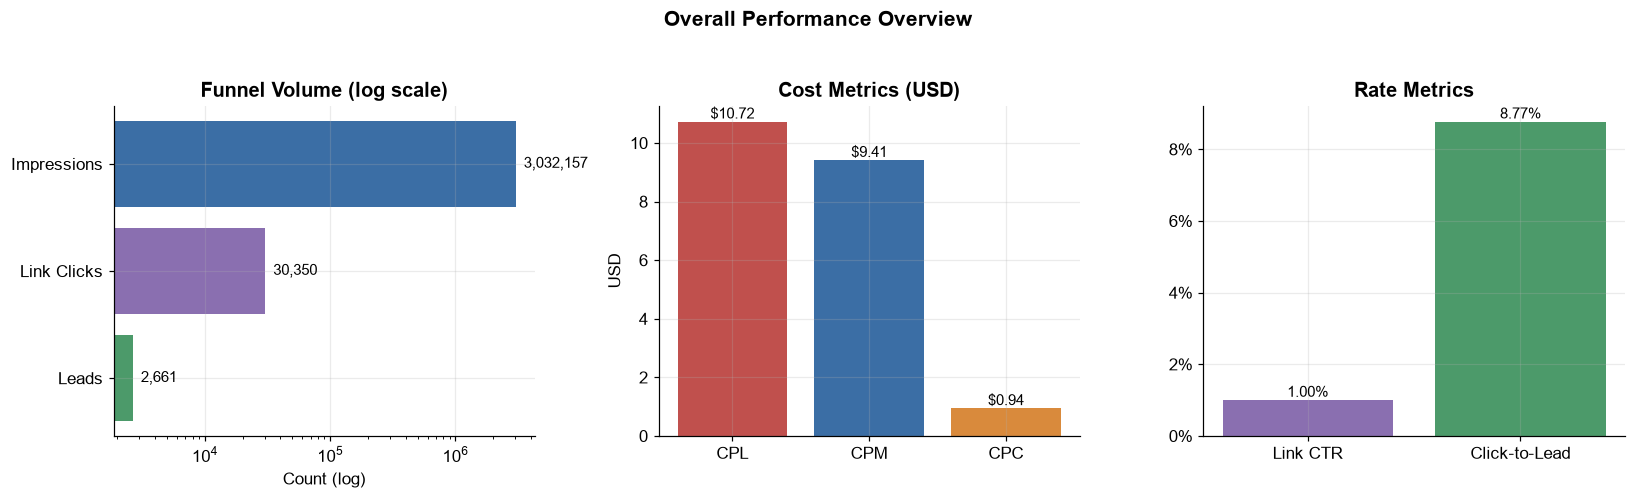

In [7]:

# 整体核心指标概览图
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

# (1) 漏斗规模（对数横轴，避免量级差异压扁小值）
funnel = pd.Series({"Impressions": total_impr, "Link Clicks": total_clicks, "Leads": total_leads})
bars = axes[0].barh(funnel.index[::-1], funnel.values[::-1], color=[C_LEADS, C_RATE, C_SPEND])
axes[0].set_xscale("log")
axes[0].set_title("Funnel Volume (log scale)")
axes[0].set_xlabel("Count (log)")
for b, v in zip(bars, funnel.values[::-1]):
    axes[0].text(v, b.get_y() + b.get_height() / 2, f"  {v:,.0f}", va="center", fontsize=10)

# (2) 成本指标
cost = pd.Series({"CPL": overall_cpl, "CPM": overall_cpm, "CPC": overall_cpc})
bars = axes[1].bar(cost.index, cost.values, color=[C_CPL, C_SPEND, C_WARN])
axes[1].set_title("Cost Metrics (USD)")
axes[1].set_ylabel("USD")
for b, v in zip(bars, cost.values):
    axes[1].text(b.get_x() + b.get_width() / 2, v, f"${v:,.2f}", ha="center", va="bottom", fontsize=10)

# (3) 比率指标
rate = pd.Series({"Link CTR": overall_link_ctr, "Click-to-Lead": overall_c2l})
bars = axes[2].bar(rate.index, rate.values, color=[C_RATE, C_LEADS])
axes[2].set_title("Rate Metrics")
axes[2].yaxis.set_major_formatter(lambda x, p: f"{x:.0%}")
for b, v in zip(bars, rate.values):
    axes[2].text(b.get_x() + b.get_width() / 2, v, f"{v:.2%}", ha="center", va="bottom", fontsize=10)

fig.suptitle("Overall Performance Overview", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()



### 4.3 结果观察

- 全周期共投入 **$28,537.57**，获得 **3,032,157** 次展示、**30,350** 次链接点击与 **2,661** 个 Leads。
- 整体 **CPL 约 $10.72**，整体 **Link CTR 约 1.00%**，整体 **Click-to-Lead Rate 约 8.77%**，**CPC 约 $0.94**，**CPM 约 $9.41**。
- 从漏斗看，展示到链接点击的转化效率（约 1%）是整条漏斗中最"窄"的一段，点击到线索的转化率相对更高（约 8.8%）。

### 4.4 业务含义与局限

整体 CPL 约 $10.72 仅是本数据集在 2026-05-01 至 2026-07-17 期间的平均水平，**不能**直接当作目标成本或行业标准。缺少线索质量与成交数据前，无法判断该成本是否"合理"。



## 五、周度趋势分析

### 5.1 分析目的

观察投放规模与获客效率随时间的变化，识别放量/收缩阶段与成本波动。

### 5.2 关键指标与口径

- 按 `week_start`（报告开始日期，日期类型）聚合，**按真实日期升序排序**，不依赖字符串拼接；
- 周度 `CPL = 当周 Spend / 当周 Leads`，**不对逐行 CPL 求平均**；
- 周度 `Link CTR = 当周 Link Clicks / 当周 Impressions`；`Click-to-Lead Rate = 当周 Leads / 当周 Link Clicks`。

**报告区间说明：** 11 份周报的首尾日期连续相接，本 Notebook 以"每周报一行"的方式独立统计，不做跨周累加去重，因此合计口径等同于逐周相加。


In [8]:

# =========================================================
# 5. 周度趋势
# =========================================================
weekly = (df_analysis
          .groupby("week_start")
          .agg(Spend=("已花费金额 (USD)", "sum"),
               Impressions=("展示次数", "sum"),
               Link_Clicks=("链接点击量", "sum"),
               Leads=("成效", "sum"))
          .sort_index()
          .reset_index())

weekly["CPL"] = np.where(weekly["Leads"] > 0, weekly["Spend"] / weekly["Leads"], np.nan)
weekly["Link_CTR"] = np.where(weekly["Impressions"] > 0, weekly["Link_Clicks"] / weekly["Impressions"], np.nan)
weekly["Click_to_Lead_Rate"] = np.where(weekly["Link_Clicks"] > 0, weekly["Leads"] / weekly["Link_Clicks"], np.nan)
weekly["week_label"] = weekly["week_start"].dt.strftime("%m-%d")

weekly_view = weekly[["week_label", "Spend", "Impressions", "Link_Clicks", "Leads", "CPL", "Link_CTR", "Click_to_Lead_Rate"]].copy()
weekly_view.columns = ["周 (开始)", "Spend", "Impressions", "Link Clicks", "Leads", "CPL", "Link CTR", "Click-to-Lead Rate"]
weekly_fmt = weekly_view.copy()
for c in ["Spend", "CPL"]:
    weekly_fmt[c] = weekly_fmt[c].map(fmt_money)
for c in ["Impressions", "Link Clicks", "Leads"]:
    weekly_fmt[c] = weekly_fmt[c].map(fmt_int)
for c in ["Link CTR", "Click-to-Lead Rate"]:
    weekly_fmt[c] = weekly_fmt[c].map(fmt_pct)
show(weekly_fmt)


,周 (开始),Spend,Impressions,Link Clicks,Leads,CPL,Link CTR,Click-to-Lead Rate
0,05-01,"$3,073.61","353,959","3,773",296,$10.38,1.07%,7.85%
1,05-08,"$3,307.06","335,789","3,569",261,$12.67,1.06%,7.31%
2,05-15,"$4,391.11","462,201","4,810",324,$13.55,1.04%,6.74%
3,05-22,"$4,348.02","414,091","4,693",457,$9.51,1.13%,9.74%
4,05-29,"$4,139.92","415,358","4,461",409,$10.12,1.07%,9.17%
5,06-05,"$3,010.60","319,292","3,163",368,$8.18,0.99%,11.63%
6,06-12,"$2,316.17","268,540","2,137",226,$10.25,0.80%,10.58%
7,06-19,"$1,819.96","222,555","1,801",164,$11.10,0.81%,9.11%
8,06-26,$600.26,"77,300",634,63,$9.53,0.82%,9.94%
9,07-03,$506.52,"37,481",329,25,$20.26,0.88%,7.60%


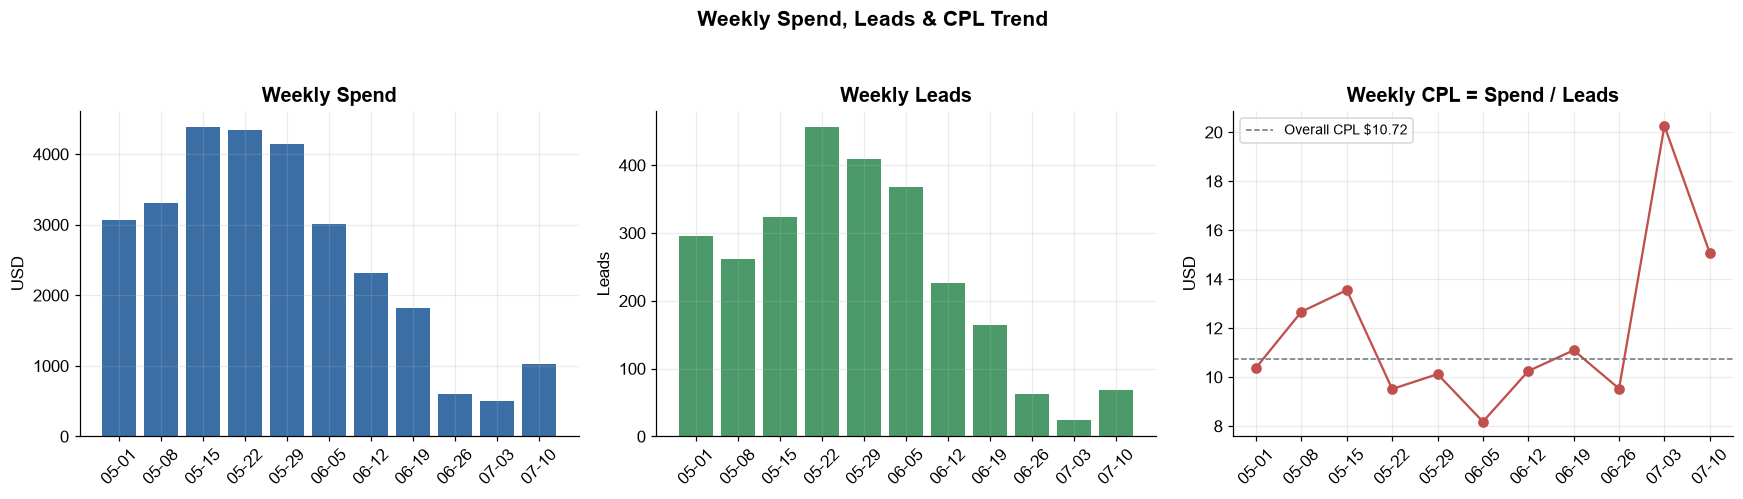

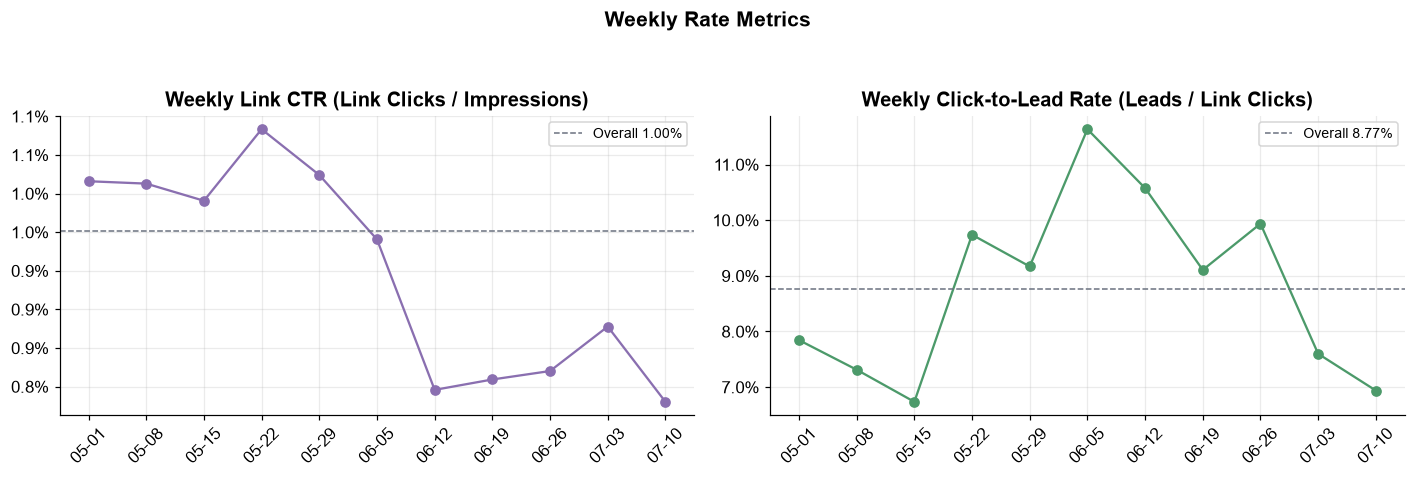

In [9]:

# 图 1：Spend / Leads / CPL —— 每个指标独立坐标轴，避免量纲混用
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].bar(weekly["week_label"], weekly["Spend"], color=C_SPEND)
axes[0].set_title("Weekly Spend")
axes[0].set_ylabel("USD")
axes[0].tick_params(axis="x", labelrotation=45)

axes[1].bar(weekly["week_label"], weekly["Leads"], color=C_LEADS)
axes[1].set_title("Weekly Leads")
axes[1].set_ylabel("Leads")
axes[1].tick_params(axis="x", labelrotation=45)

axes[2].plot(weekly["week_label"], weekly["CPL"], marker="o", color=C_CPL)
axes[2].axhline(overall_cpl, ls="--", color=C_NEUT, lw=1, label=f"Overall CPL ${overall_cpl:.2f}")
axes[2].set_title("Weekly CPL = Spend / Leads")
axes[2].set_ylabel("USD")
axes[2].tick_params(axis="x", labelrotation=45)
axes[2].legend(fontsize=9)

fig.suptitle("Weekly Spend, Leads & CPL Trend", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# 图 2：Link CTR 与 Click-to-Lead Rate
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(weekly["week_label"], weekly["Link_CTR"], marker="o", color=C_RATE)
axes[0].axhline(overall_link_ctr, ls="--", color=C_NEUT, lw=1, label=f"Overall {overall_link_ctr:.2%}")
axes[0].set_title("Weekly Link CTR (Link Clicks / Impressions)")
axes[0].yaxis.set_major_formatter(lambda x, p: f"{x:.1%}")
axes[0].tick_params(axis="x", labelrotation=45)
axes[0].legend(fontsize=9)

axes[1].plot(weekly["week_label"], weekly["Click_to_Lead_Rate"], marker="o", color=C_LEADS)
axes[1].axhline(overall_c2l, ls="--", color=C_NEUT, lw=1, label=f"Overall {overall_c2l:.2%}")
axes[1].set_title("Weekly Click-to-Lead Rate (Leads / Link Clicks)")
axes[1].yaxis.set_major_formatter(lambda x, p: f"{x:.1%}")
axes[1].tick_params(axis="x", labelrotation=45)
axes[1].legend(fontsize=9)

fig.suptitle("Weekly Rate Metrics", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()



### 5.3 结果观察

- **规模：** Spend 在 05-15 当周达到最高（约 $4,391），随后逐步收缩，07-03 当周降至最低（约 $507），07-10 当周回升至约 $1,024。
- **Leads：** 与 Spend 大体同步，05-22 当周最高（457 个），此后随投放规模下降而回落。
- **CPL：** 成本最低出现在 06-05 当周（约 $8.18），最高出现在 07-03 当周（约 $20.26）。需要注意 07-03 当周 Spend 与 Leads 都处于低谷（仅 25 个 Leads），CPL 波动可能来自小样本。
- **比值：** Link CTR 由前期的约 1.1% 缓慢下滑至后期的约 0.8%；Click-to-Lead Rate 前期上升，随后在 7%–11% 区间波动。

### 5.4 业务含义与局限

后半段的 CPL 上升与 Link CTR 下滑同时出现，提示"点击效率变差"可能是成本上升的一个线索，但**这只是时间上的同步变化，不能据此断定因果**。周度数据仅反映历史投放表现，且 07 月周度 Leads 数量偏低，趋势判断需谨慎。



## 六、国家/地区表现分析

### 6.1 分析目的

不同国家的市场规模、竞争程度与产品适配度不同，需要从国家维度拆解投放表现，识别：

1. 哪些国家贡献了主要 Leads；
2. 哪些国家在同等规模下 CPL 更低；
3. 哪些国家虽然 CPL 很低，但样本量太小、稳定性存疑。

> 本节将原先分散在多个单元格中的国家汇总与重复的 Spend x CPL 图表**合并为唯一一个模块**，所有指标使用统一公式。

### 6.2 关键指标与口径

国家表包含：Country、Spend、Impressions、Link Clicks、Leads、CPL、Link CTR、Click-to-Lead Rate、CPC、CPM、Lead Share。

- `Link CTR` 严格使用 **链接点击量 / 展示次数** 计算，**不使用**原始字段 `点击率（全部）`；
- 所有比率基于聚合总量重算；金额保留两位小数；比率以百分比显示；
- `unknown` 单独保留为一行并标注，不并入正常国家。


In [10]:

# =========================================================
# 6. 国家/地区汇总（唯一模块）
# =========================================================
COUNTRY_NAME = {
    "AR": "Argentina", "AT": "Austria", "AU": "Australia", "BE": "Belgium", "BR": "Brazil",
    "CH": "Switzerland", "CZ": "Czechia", "DE": "Germany", "DK": "Denmark", "ES": "Spain",
    "FI": "Finland", "FR": "France", "GB": "United Kingdom", "HU": "Hungary", "IE": "Ireland",
    "IS": "Iceland", "IT": "Italy", "JP": "Japan", "LV": "Latvia", "NL": "Netherlands",
    "NO": "Norway", "NZ": "New Zealand", "PL": "Poland", "PT": "Portugal", "SE": "Sweden",
    "SI": "Slovenia", "SK": "Slovakia", "US": "United States", "unknown": "Unknown",
}

df_analysis["country_name"] = (df_analysis["国家/地区"].astype(str).str.strip()
                               .map(COUNTRY_NAME).fillna(df_analysis["国家/地区"].astype(str).str.strip()))

country = (df_analysis
           .groupby("country_name")
           .agg(Spend=("已花费金额 (USD)", "sum"),
                Impressions=("展示次数", "sum"),
                **{"Link Clicks": ("链接点击量", "sum")},
                Leads=("成效", "sum"))
           .reset_index()
           .rename(columns={"country_name": "Country"}))

country["CPL"] = np.where(country["Leads"] > 0, country["Spend"] / country["Leads"], np.nan)
country["Link CTR"] = np.where(country["Impressions"] > 0, country["Link Clicks"] / country["Impressions"], np.nan)
country["Click-to-Lead Rate"] = np.where(country["Link Clicks"] > 0, country["Leads"] / country["Link Clicks"], np.nan)
country["CPC"] = np.where(country["Link Clicks"] > 0, country["Spend"] / country["Link Clicks"], np.nan)
country["CPM"] = np.where(country["Impressions"] > 0, country["Spend"] / country["Impressions"] * 1000, np.nan)
country["Lead Share"] = np.where(total_leads > 0, country["Leads"] / total_leads, np.nan)
country = country.sort_values("Leads", ascending=False).reset_index(drop=True)

country_fmt = country.copy()
for c in ["Spend", "CPL", "CPC", "CPM"]:
    country_fmt[c] = country_fmt[c].map(fmt_money)
for c in ["Impressions", "Link Clicks", "Leads"]:
    country_fmt[c] = country_fmt[c].map(fmt_int)
for c in ["Link CTR", "Click-to-Lead Rate", "Lead Share"]:
    country_fmt[c] = country_fmt[c].map(fmt_pct)
show(country_fmt)

print("国家/地区数量（不含 Unknown）：", (country["Country"] != "Unknown").sum())
low_countries = country.loc[(country["Leads"] < MIN_LEADS) & (country["Country"] != "Unknown"), "Country"]
print("Leads < %d 的低样本国家：" % MIN_LEADS, list(low_countries))


国家/地区数量（不含 Unknown）： 28
Leads < 10 的低样本国家： ['Austria', 'Japan', 'Switzerland', 'Slovenia', 'Latvia']


,Country,Spend,Impressions,Link Clicks,Leads,CPL,Link CTR,Click-to-Lead Rate,CPC,CPM,Lead Share
0,United States,"$3,403.97","160,695","3,201",495,$6.88,1.99%,15.46%,$1.06,$21.18,18.60%
1,Poland,"$3,018.79","736,220","5,189",347,$8.70,0.70%,6.69%,$0.58,$4.10,13.04%
2,Australia,"$4,611.65","261,774","2,673",305,$15.12,1.02%,11.41%,$1.73,$17.62,11.46%
3,Argentina,$378.77,"129,182","1,073",260,$1.46,0.83%,24.23%,$0.35,$2.93,9.77%
4,United Kingdom,"$2,987.12","222,351","2,404",196,$15.24,1.08%,8.15%,$1.24,$13.43,7.37%
5,Brazil,$318.88,"58,606",772,171,$1.86,1.32%,22.15%,$0.41,$5.44,6.43%
6,Czechia,"$1,784.07","274,472","3,398",171,$10.43,1.24%,5.03%,$0.53,$6.50,6.43%
7,New Zealand,"$2,350.25","194,597","1,958",171,$13.74,1.01%,8.73%,$1.20,$12.08,6.43%
8,Hungary,$536.65,"118,649","1,237",122,$4.40,1.04%,9.86%,$0.43,$4.52,4.58%
9,France,"$1,170.53","168,958","1,579",115,$10.18,0.93%,7.28%,$0.74,$6.93,4.32%


说明：仅展示 Leads >= 10 的国家；更低样本国家因波动大未纳入排名，但仍保留在上表中。


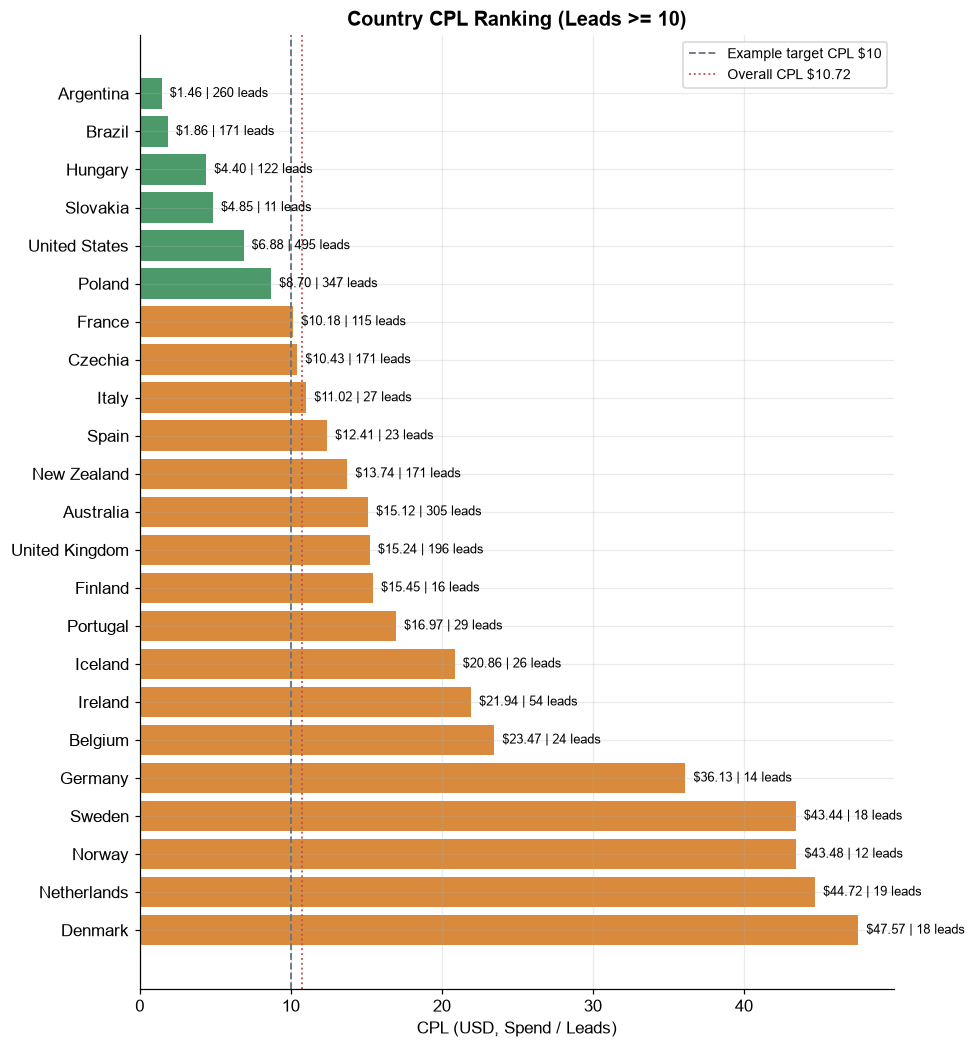

In [11]:

# 国家 CPL 排名图（过滤低样本国家 + 标注 Leads）
plot_country = (country[(country["Country"] != "Unknown") & (country["Leads"] >= MIN_LEADS)]
                .sort_values("CPL").reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, max(5, 0.42 * len(plot_country))))
colors = [C_LEADS if v <= TARGET_CPL else C_WARN for v in plot_country["CPL"]]
bars = ax.barh(plot_country["Country"], plot_country["CPL"], color=colors)
ax.axvline(TARGET_CPL, ls="--", color=C_NEUT, lw=1.2, label=f"Example target CPL ${TARGET_CPL:.0f}")
ax.axvline(overall_cpl, ls=":", color=C_CPL, lw=1.2, label=f"Overall CPL ${overall_cpl:.2f}")
ax.invert_yaxis()
ax.set_xlabel("CPL (USD, Spend / Leads)")
ax.set_title(f"Country CPL Ranking (Leads >= {MIN_LEADS})")
for b, (_, r) in zip(bars, plot_country.iterrows()):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2,
            f"  ${r['CPL']:.2f} | {int(r['Leads'])} leads", va="center", fontsize=8.5)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

print("说明：仅展示 Leads >= %d 的国家；更低样本国家因波动大未纳入排名，但仍保留在上表中。" % MIN_LEADS)


低样本国家（Leads < 10，仅作参考，不据此下结论）：
  Japan: 6 leads, CPL $21.48 | Austria: 9 leads, CPL $35.56 | Slovenia: 1 leads, CPL $56.68 | Switzerland: 1 leads, CPL $145.49


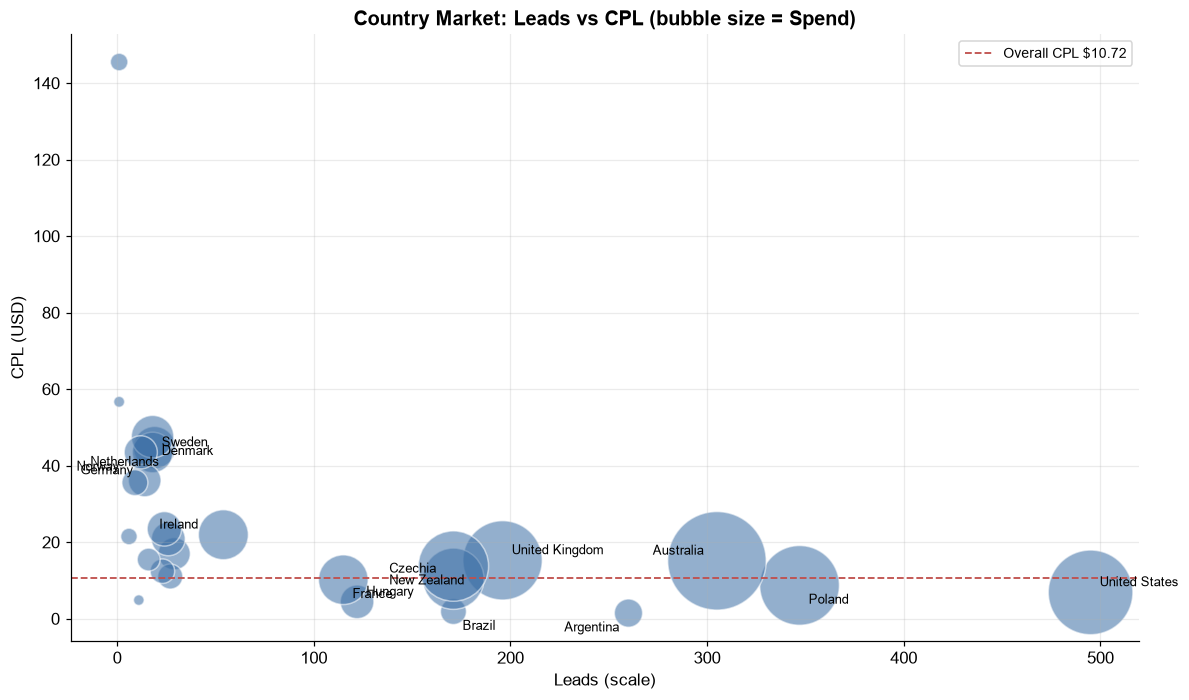

In [12]:

# 国家市场气泡图：横轴 Leads，纵轴 CPL，气泡大小 = Spend
bub = country[(country["Country"] != "Unknown") & (country["Leads"] > 0)].copy()

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(bub["Leads"], bub["CPL"], s=bub["Spend"] * 0.9, alpha=0.55, color=C_SPEND, edgecolor="white")
ax.axhline(overall_cpl, ls="--", color=C_CPL, lw=1.2, label=f"Overall CPL ${overall_cpl:.2f}")

# 只标注主要市场（Leads >= 30）与成本明显偏高的市场（CPL >= 35 且 Leads >= 10），
# 其余点为低样本或相近点，避免标签重叠。
label_mask = (bub["Leads"] >= 30) | ((bub["CPL"] >= 35) & (bub["Leads"] >= MIN_LEADS))
offsets = [(6, 4), (6, -12), (-42, 4), (-42, -12)]
for k, (_, r) in enumerate(bub[label_mask].iterrows()):
    ax.annotate(r["Country"], (r["Leads"], r["CPL"]), xytext=offsets[k % len(offsets)],
                textcoords="offset points", fontsize=8.5)
ax.set_xlabel("Leads (scale)")
ax.set_ylabel("CPL (USD)")
ax.set_title("Country Market: Leads vs CPL (bubble size = Spend)")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

low = bub[bub["Leads"] < MIN_LEADS].sort_values("CPL")
print("低样本国家（Leads < %d，仅作参考，不据此下结论）：" % MIN_LEADS)
if len(low):
    print("  " + " | ".join(f"{r.Country}: {int(r.Leads)} leads, CPL ${r.CPL:.2f}" for r in low.itertuples()))



### 6.3 结果观察

- **规模最大的市场：** US 贡献 495 个 Leads（Lead Share 约 18.6%，CPL 约 $6.88），PL 贡献 347 个（约 13.0%，CPL 约 $8.70），AU 贡献 305 个（约 11.5%）。其中 US 与 PL 在较大规模下仍保持低于整体水平的 CPL。
- **极低 CPL 但花费较小：** AR（260 Leads，CPL 约 $1.46）与 BR（171 Leads，CPL 约 $1.86）CPL 显著低于整体，但两者 Spend 分别约 $379 与 $319，属于"低成本、尚未大规模投放"的市场，需结合线索质量判断是否可扩量。
- **高 CPL 且样本量小：** NL（$44.72）、DK（$47.57）、SE（$43.44）、NO（$43.48）等北欧/西欧市场 CPL 偏高，但 Leads 多在 12–19 之间，属于低样本，波动较大。
- **中等规模但成本偏高：** AU 拥有第二大 Spend（约 $4,612）与 305 Leads，但 CPL 约 $15.12，明显高于整体水平，是本数据中最值得进一步排查的市场之一。

### 6.4 业务含义与局限

US、PL 具备"规模 + 相对低成本"的特征，AR、BR 则呈现"极低成本但小规模"。但低 CPL **不等于**高质量：AR、BR 的低 CPL 是否可持续、线索是否有效，需要销售跟进数据验证。北欧国家的偏高 CPL 受小样本影响较大，暂不宜据此直接调整预算。



## 七、Campaign 表现分析

### 7.1 分析目的

在 Campaign 粒度上比较效率，识别高花费/高 Lead 的主力系列，以及"低花费偶然低 CPL"的干扰项。

### 7.2 关键指标与口径

保留字段：Campaign Name、Spend、Leads、CPL、Link CTR、CPC、CPM、Click-to-Lead Rate。

**筛选条件说明：** 排名图只展示 `Leads >= 10` 的 Campaign，以降低极小样本造成的 CPL 失真；全量结果仍保留在表中。


In [13]:

# =========================================================
# 7. Campaign 汇总
# =========================================================
def short_campaign_name(name):
    """把冗长 Campaign 名称压缩为 '型号 | 变体 | 日期' 形式，便于图表展示。"""
    s = str(name)
    m = re.match(r"^Leads_New_FJD_(.+?)_", s)
    model = m.group(1) if m else "NA"
    model = {"高尔夫应用场景": "Golf"}.get(model, model)
    if re.search(r"[\u4e00-\u9fff]", model):
        model = "Other"
    var = re.search(r"[（(]([^（）()]+)[）)]", s)
    var = var.group(1).strip() if var else ""
    var = var.replace("Robotic Lawn Mower", "RLM").strip()
    var = {"全球": "Global"}.get(var, var)
    # 图表标签使用 ASCII，避免缺少中文字体时出现乱码
    if re.search(r"[\u4e00-\u9fff]", var):
        var = "Variant"
    date = re.search(r"(\d{8})$", s)
    date = date.group(1)[4:] if date else ""
    return " | ".join(x for x in [model, var, date] if x)

campaign = (df_analysis
            .groupby("广告系列名称")
            .agg(Spend=("已花费金额 (USD)", "sum"),
                 Impressions=("展示次数", "sum"),
                 **{"Link Clicks": ("链接点击量", "sum")},
                 Leads=("成效", "sum"))
            .reset_index()
            .rename(columns={"广告系列名称": "Campaign Name"}))
campaign["CPL"] = np.where(campaign["Leads"] > 0, campaign["Spend"] / campaign["Leads"], np.nan)
campaign["Link CTR"] = np.where(campaign["Impressions"] > 0, campaign["Link Clicks"] / campaign["Impressions"], np.nan)
campaign["CPC"] = np.where(campaign["Link Clicks"] > 0, campaign["Spend"] / campaign["Link Clicks"], np.nan)
campaign["CPM"] = np.where(campaign["Impressions"] > 0, campaign["Spend"] / campaign["Impressions"] * 1000, np.nan)
campaign["Click-to-Lead Rate"] = np.where(campaign["Link Clicks"] > 0, campaign["Leads"] / campaign["Link Clicks"], np.nan)
campaign["Short Name"] = campaign["Campaign Name"].map(short_campaign_name)
campaign = campaign.sort_values("Leads", ascending=False).reset_index(drop=True)

campaign_fmt = campaign[["Campaign Name", "Spend", "Leads", "CPL", "Link CTR", "CPC", "CPM", "Click-to-Lead Rate"]].copy()
for c in ["Spend", "CPL", "CPC", "CPM"]:
    campaign_fmt[c] = campaign_fmt[c].map(fmt_money)
for c in ["Link CTR", "Click-to-Lead Rate"]:
    campaign_fmt[c] = campaign_fmt[c].map(fmt_pct)
campaign_fmt["Leads"] = campaign_fmt["Leads"].map(fmt_int)
show(campaign_fmt)

print("Campaign 总数：", len(campaign), "| Leads >= %d 的 Campaign：%d" % (MIN_LEADS, (campaign["Leads"] >= MIN_LEADS).sum()))


Campaign 总数： 34 | Leads >= 10 的 Campaign：33


,Campaign Name,Spend,Leads,CPL,Link CTR,CPC,CPM,Click-to-Lead Rate
0,Leads_New_FJD_RM21_FJD BU (Robotic Lawn Mower 2）_20260126,"$4,778.71",359,$13.31,0.92%,$0.94,$8.71,7.08%
1,Leads_New_FJD_RCM01_FJD BU (Robotic Lawn Mower 4）_20260402,$850.15,213,$3.99,2.95%,$0.73,$21.39,18.17%
2,Leads_New_FJD_RLM02_FJD BU (Robotic Lawn Mower 2）_20260126,"$1,655.95",192,$8.62,0.76%,$0.43,$3.23,4.96%
3,Leads_New_FJD_RLM01_FJD BU (Robotic Lawn Mower 4）_20260126,"$1,716.88",173,$9.92,1.19%,$1.61,$19.22,16.21%
4,Leads_New_FJD_RLM01_FJD BU (Robotic Lawn Mower 2）_20260126,"$1,906.47",155,$12.30,0.94%,$0.79,$7.40,6.38%
5,Leads_New_FJD_RM21_（全球）_20241231,$427.32,150,$2.85,1.14%,$0.56,$6.42,19.69%
6,Leads_New_FJD_RCM01_FJD BU (Robotic Lawn Mower 6)_20260509,"$1,646.30",149,$11.05,1.28%,$1.27,$16.24,11.48%
7,Leads_New_FJD_RLM01_FJD BU (Robotic Lawn Mower 7)_20260518,$110.07,133,$0.83,1.53%,$0.21,$3.16,24.86%
8,Leads_New_FJD_RLM02_FJD BU (Robotic Lawn Mower 1）_20260126,"$1,153.13",110,$10.48,0.79%,$1.00,$7.91,9.52%
9,Leads_New_FJD_RM21_FJD BU (Robotic Lawn Mower 4）_20260126,$836.94,109,$7.68,3.04%,$0.87,$26.46,11.33%


低花费且低 CPL 的 Campaign（需谨慎看待，规模小、可复制性未知）：
  RLM01 | RLM 7 | 0518: Spend $110, 133 leads, CPL $0.83
  RM21 | RLM 7 | 0518: Spend $109, 93 leads, CPL $1.17
  RM21 | Global | 1231: Spend $427, 150 leads, CPL $2.85
  RLM01 | RLM group1 | 0303: Spend $380, 72 leads, CPL $5.28
  RLM02 | RLM 3 | 1010: Spend $116, 18 leads, CPL $6.47
  RLM02 | RLM 6 | 0509: Spend $195, 22 leads, CPL $8.88


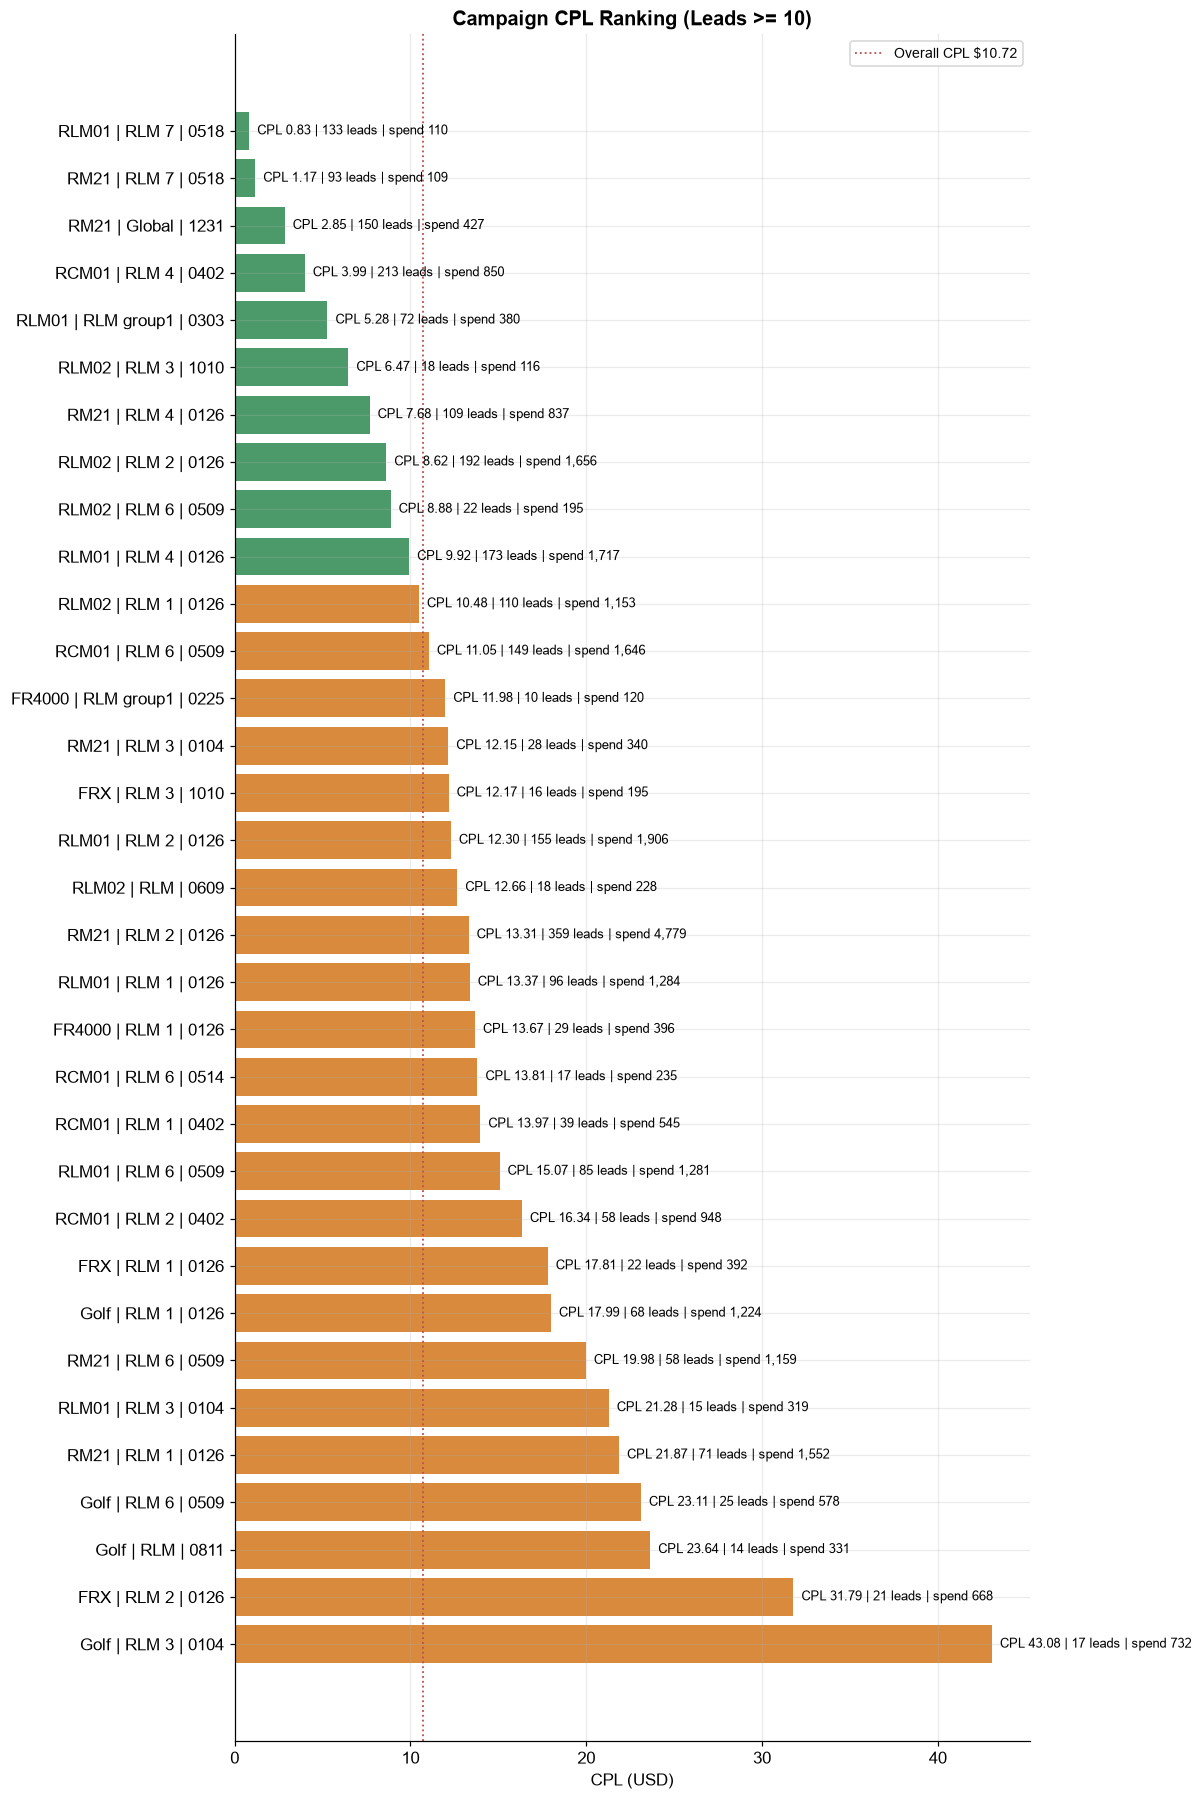

In [14]:

# Campaign CPL 排名图（Leads >= MIN_LEADS，标注 Leads 与 Spend）
plot_campaign = (campaign[campaign["Leads"] >= MIN_LEADS]
                 .sort_values("CPL").reset_index(drop=True))

fig, ax = plt.subplots(figsize=(11, max(5, 0.5 * len(plot_campaign))))
colors = [C_LEADS if v <= TARGET_CPL else C_WARN for v in plot_campaign["CPL"]]
bars = ax.barh(plot_campaign["Short Name"], plot_campaign["CPL"], color=colors)
ax.axvline(overall_cpl, ls=":", color=C_CPL, lw=1.2, label=f"Overall CPL ${overall_cpl:.2f}")
ax.invert_yaxis()
ax.set_xlabel("CPL (USD)")
ax.set_title(f"Campaign CPL Ranking (Leads >= {MIN_LEADS})")
for b, (_, r) in zip(bars, plot_campaign.iterrows()):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2,
            f"  CPL {r['CPL']:.2f} | {int(r['Leads'])} leads | spend {r['Spend']:,.0f}",
            va="center", fontsize=8.5)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

low_spend = plot_campaign[(plot_campaign["Spend"] < campaign["Spend"].median()) & (plot_campaign["CPL"] < TARGET_CPL)]
print("低花费且低 CPL 的 Campaign（需谨慎看待，规模小、可复制性未知）：")
if len(low_spend):
    print("  " + "\n  ".join(
        f"{r['Short Name']}: Spend ${r['Spend']:,.0f}, {int(r['Leads'])} leads, CPL ${r['CPL']:.2f}"
        for _, r in low_spend.iterrows()))



### 7.3 结果观察

- **主力 Campaign：** `RM21 | RLM 2 | 0126` 花费最高（约 $4,779）、Leads 最多（359 个），但 CPL 约 $13.31，高于整体；`RCM01 | RLM 4 | 0402` 以约 $850 花费获得 213 个 Leads，CPL 约 $3.99，规模与效率兼具。
- **低花费高性价比：** `RM21 全球`（约 $427，150 Leads，CPL 约 $2.85）与 `RLM01 | RLM 7 | 0518`（约 $110，133 Leads，CPL 约 $0.83）CPL 极低，但花费明显低于主力系列，属于"小规模高性价比"，能否放大尚待验证。
- **高花费高成本：** `RM21 | RLM 2 | 0126` 花费最大却 CPL 高于整体，是成本优化的重点观察对象。

### 7.4 业务含义与局限

CPL 排名必须与 Leads、Spend 一起看：低花费 Campaign 的极低 CPL 很可能来自素材/受众的偶然匹配，不能直接判定为"优秀"并放量。表中同时标注了 Leads 与 Spend，便于识别样本量。缺少线索质量数据前，无法判断低 CPL 是否带来有效商机。



## 八、产品型号 x 国家/地区分析

### 8.1 分析目的

观察各产品型号在不同国家的投放表现，判断是否存在"某型号更适合某市场"的信号。

### 8.2 关键指标与口径

- 使用**统一后的 `product_model` 字段**（见 3.4），型号不可靠的记录不会进入交叉结论；
- 展示 Spend、Leads、CPL 等关键指标，CPL 按 `Spend / Leads` 计算；
- 热力图中没有数据的组合保留为**空白**，不视作 CPL=0；
- `Leads < 10` 的组合在热力图中以 `*` 标注，提示样本量偏小。


In [15]:

# =========================================================
# 8. 产品型号汇总 与 产品 x 国家交叉
# =========================================================
product = (df_analysis
           .groupby("product_model")
           .agg(Spend=("已花费金额 (USD)", "sum"),
                Impressions=("展示次数", "sum"),
                **{"Link Clicks": ("链接点击量", "sum")},
                Leads=("成效", "sum"))
           .reset_index())
product["CPL"] = np.where(product["Leads"] > 0, product["Spend"] / product["Leads"], np.nan)
product["Link CTR"] = np.where(product["Impressions"] > 0, product["Link Clicks"] / product["Impressions"], np.nan)
product["Click-to-Lead Rate"] = np.where(product["Link Clicks"] > 0, product["Leads"] / product["Link Clicks"], np.nan)
product = product.sort_values("Leads", ascending=False).reset_index(drop=True)
product["Lead Share"] = product["Leads"] / total_leads

product_fmt = product.copy()
for c in ["Spend", "CPL"]:
    product_fmt[c] = product_fmt[c].map(fmt_money)
for c in ["Impressions", "Link Clicks", "Leads"]:
    product_fmt[c] = product_fmt[c].map(fmt_int)
for c in ["Link CTR", "Click-to-Lead Rate", "Lead Share"]:
    product_fmt[c] = product_fmt[c].map(fmt_pct)
print("产品型号整体表现：")
show(product_fmt)

# 产品 x 国家 交叉表
cross = (df_analysis
         .groupby(["country_name", "product_model"])
         .agg(Spend=("已花费金额 (USD)", "sum"),
              **{"Link Clicks": ("链接点击量", "sum")},
              Impressions=("展示次数", "sum"),
              Leads=("成效", "sum"))
         .reset_index()
         .rename(columns={"country_name": "Country"}))
cross["CPL"] = np.where(cross["Leads"] > 0, cross["Spend"] / cross["Leads"], np.nan)
cross["Link CTR"] = np.where(cross["Impressions"] > 0, cross["Link Clicks"] / cross["Impressions"], np.nan)
cross["Click-to-Lead Rate"] = np.where(cross["Link Clicks"] > 0, cross["Leads"] / cross["Link Clicks"], np.nan)
cross["CPC"] = np.where(cross["Link Clicks"] > 0, cross["Spend"] / cross["Link Clicks"], np.nan)
cross["CPM"] = np.where(cross["Impressions"] > 0, cross["Spend"] / cross["Impressions"] * 1000, np.nan)
cross = cross.sort_values(["Leads"], ascending=False).reset_index(drop=True)

cross_fmt = cross.copy()
cross_fmt["Spend"] = cross_fmt["Spend"].map(fmt_money)
cross_fmt["CPL"] = cross_fmt["CPL"].map(fmt_money)
for c in ["Link CTR", "Click-to-Lead Rate"]:
    cross_fmt[c] = cross_fmt[c].map(fmt_pct)
print("\n产品 x 国家 交叉明细（按 Leads 排序，共 %d 个组合）：" % len(cross))
show(cross_fmt.head(30))


产品型号整体表现：

产品 x 国家 交叉明细（按 Leads 排序，共 89 个组合）：


,product_model,Spend,Impressions,Link Clicks,Leads,CPL,Link CTR,Click-to-Lead Rate,Lead Share
0,RM21,"$9,203.39","859,952","9,310",868,$10.60,1.08%,9.32%,32.62%
1,RLM01,"$6,997.61","786,087","6,772",729,$9.60,0.86%,10.76%,27.40%
2,RCM01,"$4,352.91","255,797","4,188",482,$9.03,1.64%,11.51%,18.11%
3,RLM02,"$3,348.66","805,006","6,275",360,$9.30,0.78%,5.74%,13.53%
4,Golf,"$2,864.58","223,525","2,315",124,$23.10,1.04%,5.36%,4.66%
5,FRX,"$1,254.13","71,543","1,024",59,$21.26,1.43%,5.76%,2.22%
6,FR4000,$516.29,"30,247",466,39,$13.24,1.54%,8.37%,1.47%


,Country,product_model,Spend,Link Clicks,Impressions,Leads,CPL,Link CTR,Click-to-Lead Rate,CPC,CPM
0,United States,RCM01,$850.15,1172.0,39754,213.0,$3.99,2.95%,18.17%,0.725384,21.385269
1,Poland,RM21,"$1,910.44",2660.0,320956,211.0,$9.05,0.83%,7.93%,0.718210,5.952340
2,Argentina,RLM01,$311.59,838.0,116911,181.0,$1.72,0.72%,21.60%,0.371826,2.665190
3,United States,RLM01,"$1,716.88",1067.0,89308,173.0,$9.92,1.19%,16.21%,1.609072,19.224258
4,Brazil,RM21,$276.17,709.0,50165,154.0,$1.79,1.41%,21.72%,0.389520,5.505233
5,Poland,RLM02,"$1,032.48",2366.0,406831,120.0,$8.60,0.58%,5.07%,0.436381,2.537855
6,United States,RM21,$836.94,962.0,31633,109.0,$7.68,3.04%,11.33%,0.870000,26.457813
7,Australia,RCM01,"$1,365.46",919.0,73410,106.0,$12.88,1.25%,11.53%,1.485814,18.600500
8,Australia,RLM01,"$1,164.97",657.0,93142,88.0,$13.24,0.71%,13.39%,1.773169,12.507487
9,Argentina,RM21,$67.18,235.0,12271,79.0,$0.85,1.92%,33.62%,0.285872,5.474696


In [16]:

# =========================================================
# 8.x 三张汇总表与整体指标的相互核对
# =========================================================
# overall / country / campaign / product / cross 都来自同一份 df_analysis，
# 只是分组方式不同；因此核心量的合计应当完全一致。
recon = pd.DataFrame({
    "口径": ["整体 (Overall)", "国家汇总合计", "Campaign 汇总合计", "产品型号汇总合计", "国家 x 产品交叉合计"],
    "Spend": [total_spend, country["Spend"].sum(), campaign["Spend"].sum(), product["Spend"].sum(), cross["Spend"].sum()],
    "Impressions": [total_impr, country["Impressions"].sum(), campaign["Impressions"].sum(), product["Impressions"].sum(), cross["Impressions"].sum()],
    "Link Clicks": [total_clicks, country["Link Clicks"].sum(), campaign["Link Clicks"].sum(), product["Link Clicks"].sum(), cross["Link Clicks"].sum()],
    "Leads": [total_leads, country["Leads"].sum(), campaign["Leads"].sum(), product["Leads"].sum(), cross["Leads"].sum()],
})

max_diff = np.abs(recon[["Spend", "Impressions", "Link Clicks", "Leads"]].sub(
    recon[["Spend", "Impressions", "Link Clicks", "Leads"]].iloc[0], axis=1)).to_numpy().max()

recon_view = recon.copy()
recon_view["Spend"] = recon_view["Spend"].map(fmt_money)
for c in ["Impressions", "Link Clicks", "Leads"]:
    recon_view[c] = recon_view[c].map(fmt_int)
print("整体 / 国家 / Campaign / 产品 / 交叉 汇总核对：")
show(recon_view)
print("各口径与整体指标的最大绝对差异：", max_diff)
print("核对结论：", "完全一致（仅分组方式不同，未发生重复累计或遗漏）" if max_diff < 1e-6
      else "存在差异，需要检查分组口径！")


整体 / 国家 / Campaign / 产品 / 交叉 汇总核对：
各口径与整体指标的最大绝对差异： 3.637978807091713e-12
核对结论： 完全一致（仅分组方式不同，未发生重复累计或遗漏）


,口径,Spend,Impressions,Link Clicks,Leads
0,整体 (Overall),"$28,537.57","3,032,157","30,350","2,661"
1,国家汇总合计,"$28,537.57","3,032,157","30,350","2,661"
2,Campaign 汇总合计,"$28,537.57","3,032,157","30,350","2,661"
3,产品型号汇总合计,"$28,537.57","3,032,157","30,350","2,661"
4,国家 x 产品交叉合计,"$28,537.57","3,032,157","30,350","2,661"


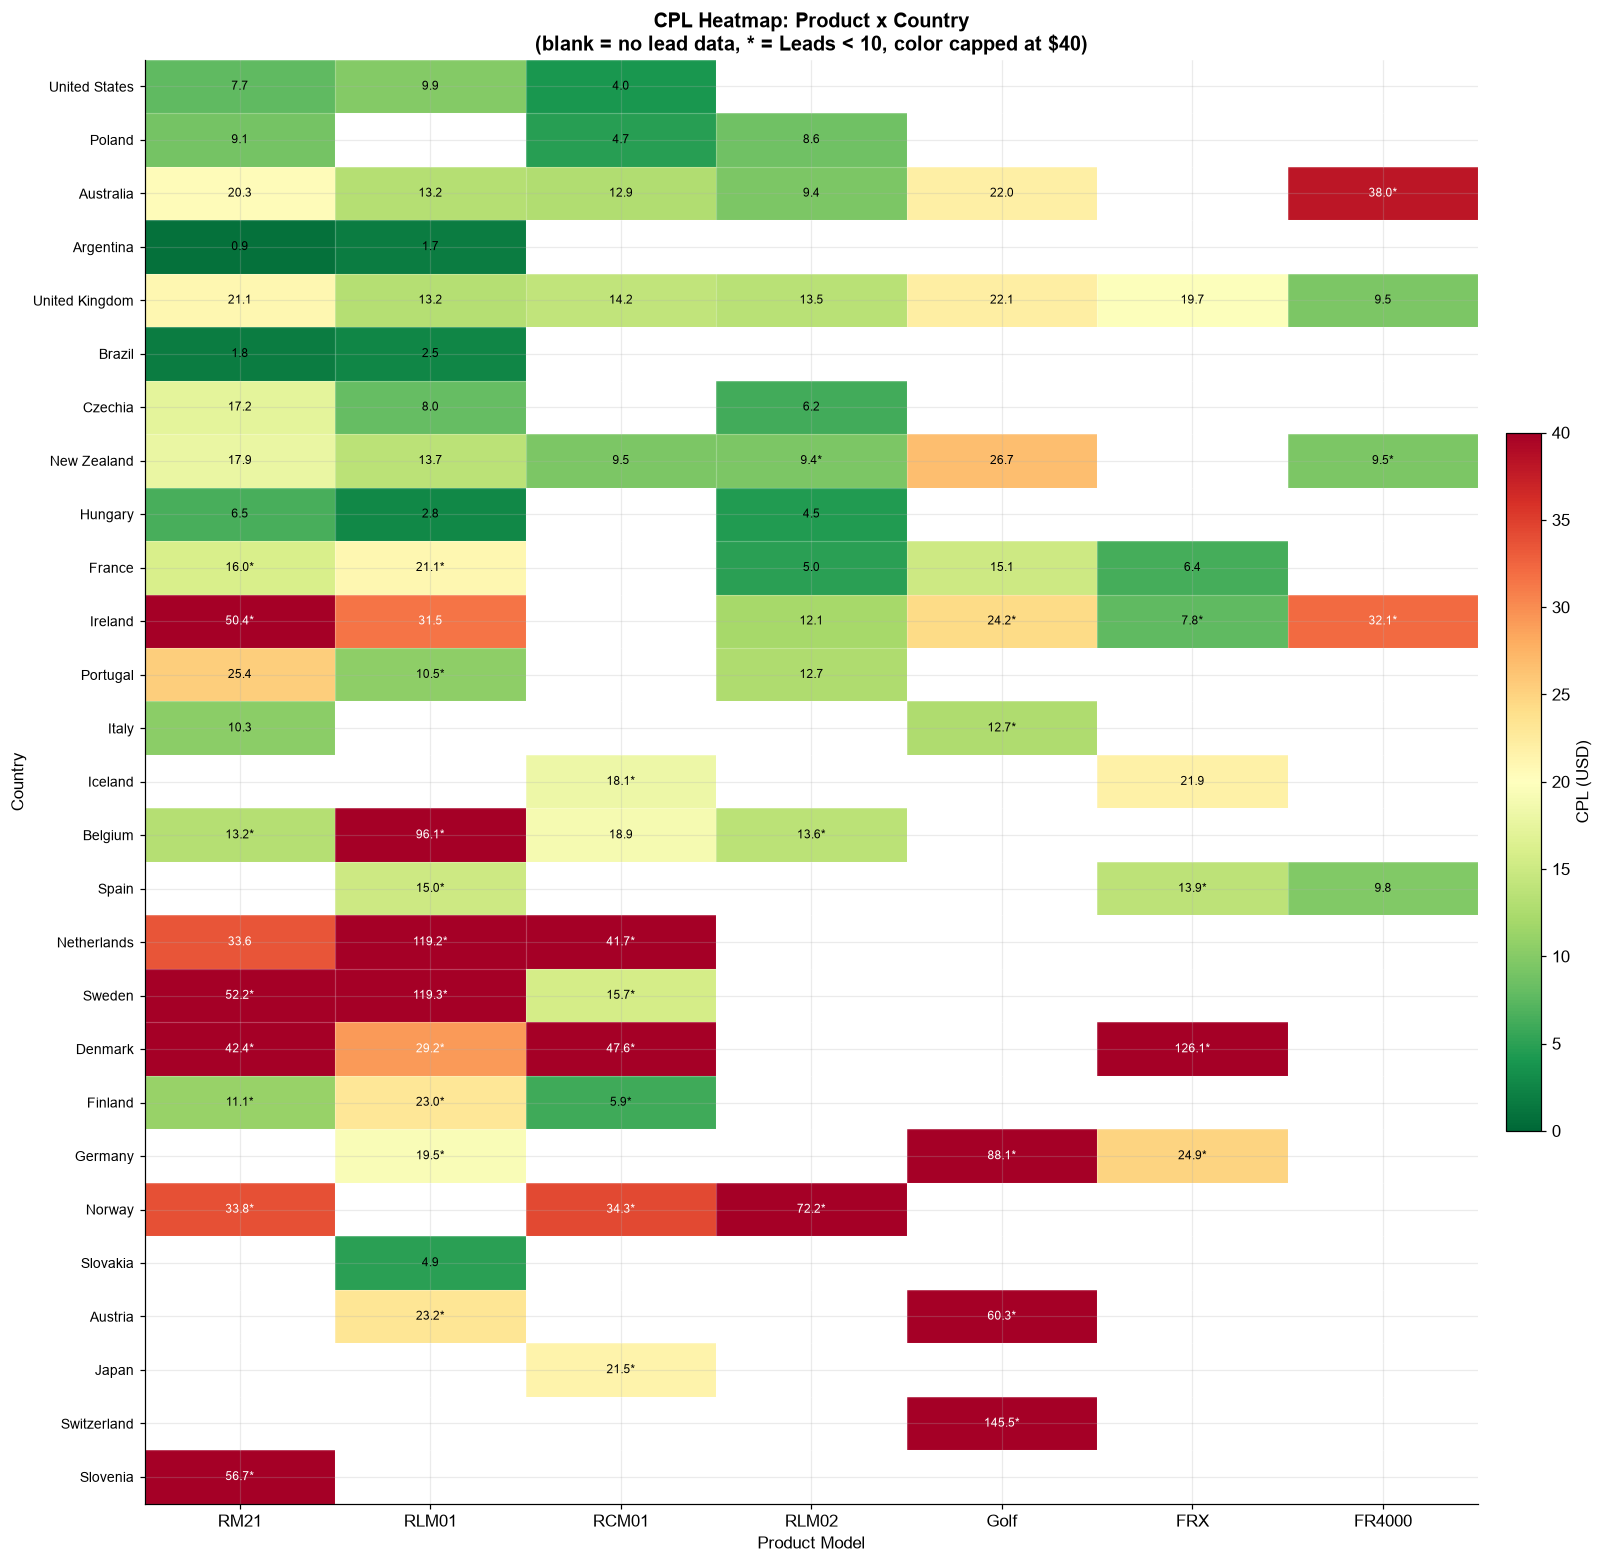

In [17]:

# 产品 x 国家 CPL 热力图
product_order = list(product.sort_values("Leads", ascending=False)["product_model"])
country_order = list(country[country["Country"] != "Unknown"].sort_values("Leads", ascending=False)["Country"])

cpl_pivot = cross.pivot(index="Country", columns="product_model", values="CPL").reindex(
    index=country_order, columns=product_order)
leads_pivot = cross.pivot(index="Country", columns="product_model", values="Leads").reindex(
    index=country_order, columns=product_order)

# 只保留至少有一个型号数据的国家
keep = cpl_pivot.notna().any(axis=1)
cpl_pivot, leads_pivot = cpl_pivot[keep], leads_pivot[keep]

cpl_masked = np.ma.masked_invalid(cpl_pivot.values)

fig, ax = plt.subplots(figsize=(1.6 * len(product_order) + 3.5, 0.42 * len(cpl_pivot) + 3))
im = ax.imshow(cpl_masked, cmap="RdYlGn_r", aspect="auto", vmin=0, vmax=40)
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("CPL (USD)")

ax.set_xticks(range(len(product_order)))
ax.set_xticklabels(product_order)
ax.set_yticks(range(len(cpl_pivot)))
ax.set_yticklabels(cpl_pivot.index, fontsize=9)
ax.set_xlabel("Product Model")
ax.set_ylabel("Country")
ax.set_title("CPL Heatmap: Product x Country\n(blank = no lead data, * = Leads < %d, color capped at $40)" % MIN_LEADS)

# 数值标注：CPL 文本 + 小样本星号
for i in range(cpl_pivot.shape[0]):
    for j in range(cpl_pivot.shape[1]):
        val = cpl_pivot.values[i, j]
        leads_val = leads_pivot.values[i, j]
        if pd.notna(val):
            star = "*" if (pd.isna(leads_val) or leads_val < MIN_LEADS) else ""
            ax.text(j, i, f"{val:.1f}{star}", ha="center", va="center", fontsize=8,
                    color="black" if val < 28 else "white")
ax.set_xticks(np.arange(-0.5, len(product_order), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(cpl_pivot), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.8)
ax.tick_params(which="minor", length=0)
fig.tight_layout()
plt.show()



### 8.3 结果观察

- **产品整体：** RM21 贡献 Leads 最多（868 个，Lead Share 约 32.6%，CPL 约 $10.60）；RLM01 以 729 个 Leads、CPL 约 $9.60 兼顾规模与效率；RCM01（482 Leads，CPL 约 $9.03）与 RLM02（360 Leads，CPL 约 $9.30）效率相近。
- **成本偏高的型号：** Golf 场景（124 Leads，CPL 约 $23.10）与 FRX（59 Leads，CPL 约 $21.26）整体 CPL 明显偏高；FR4000 规模最小（39 Leads）。
- **交叉视角：** 低 CPL 组合集中在阿根廷/巴西（如 AR-RM21 CPL 约 $0.85、AR-RLM01 约 $1.72、BR-RM21 约 $1.79），但这些市场的 Spend 普遍偏低；高样本组合中效率较好的是 US-RCM01（213 Leads，CPL 约 $3.99）与 PL-RM21（211 Leads，CPL 约 $9.05）。
- 热力图中大量格子为空白，说明并非每个型号都在每个国家投放，交叉分析只能解释**已投放**的组合。

### 8.4 业务含义与局限

产品 x 国家的低 CPL 组合多数 Spend 偏小，可能是低价市场或小规模测试，不能直接推断为"该型号最适合该国"。热力图带 `*` 的组合 Leads 不足 10 个，波动大，仅作参考。要判断产品与市场的匹配度，还需要线索质量与成交数据。



## 九、初步诊断与优化优先级

### 9.1 分析目的

在"产品 x 国家"组合粒度上，结合线索规模与漏斗指标，输出一个**初步的**优化优先级框架，为后续人工判断提供线索。

### 9.2 关键参数与口径（均为可调整的示例值，非行业标准）

| 参数 | 取值 | 含义 | 局限 |
| --- | --- | --- | --- |
| `TARGET_CPL` | $10.00 | 示例目标 CPL | 未经统计验证，也非行业标准；应由业务目标确定 |
| `MIN_LEADS` | 10 | 进入决策的最低线索门槛 | 经验值，可按数据量调整 |
| `MIN_LEADS_HIGH` | 20 | 判定"已具备一定规模" | 经验值 |
| `LOW_LINK_CTR` | 0.8% | 偏低链接点击率 | 启发式阈值，需结合投放环境 |
| `HIGH_CPC` | $1.50 | 偏高单次点击成本 | 启发式阈值 |
| `LOW_CLICK_TO_LEAD` | 5% | 偏低点击到线索转化率 | 启发式阈值 |

**性能分类规则（同时考虑 CPL 与 Leads）：**

1. `Leads < MIN_LEADS` -> **Low Data**（优先，避免小样本被误判）；
2. `CPL <= TARGET_CPL` 且 `Leads >= MIN_LEADS_HIGH` -> **Winner**；
3. `CPL <= TARGET_CPL` 且 `10 <= Leads < MIN_LEADS_HIGH` -> **Potential**（高效但规模小）；
4. `CPL > 2 x TARGET_CPL` 且 `Leads >= MIN_LEADS_HIGH` -> **Inefficient**；
5. 其余 -> **Monitor**。

> 说明：本框架的阈值是**示例参数**，用于演示"如何结合规模与成本做优先级排序"，并非经过统计检验的结论。修改上方参数即可重新计算。


In [18]:

# =========================================================
# 9.1 性能分类（同时考虑 CPL 与 Leads）
# =========================================================
decision = cross.copy()

def classify(row):
    if row["Leads"] < MIN_LEADS:
        return "Low Data"
    if row["CPL"] <= TARGET_CPL and row["Leads"] >= MIN_LEADS_HIGH:
        return "Winner"
    if row["CPL"] <= TARGET_CPL and row["Leads"] < MIN_LEADS_HIGH:
        return "Potential"
    if row["CPL"] > 2 * TARGET_CPL and row["Leads"] >= MIN_LEADS_HIGH:
        return "Inefficient"
    return "Monitor"

decision["Performance"] = decision.apply(classify, axis=1)

# 按业务优先级排序：Winner -> Potential -> Monitor -> Inefficient -> Low Data
PERF_ORDER = {"Winner": 1, "Potential": 2, "Monitor": 3, "Inefficient": 4, "Low Data": 5}
decision["Priority"] = decision["Performance"].map(PERF_ORDER)
decision = decision.sort_values(["Priority", "CPL"], ascending=[True, True]).reset_index(drop=True)

print("性能分类数量分布：")
show(decision["Performance"].value_counts().rename_axis("Performance").reset_index(name="组合数"))

show(decision[decision["Performance"].isin(["Winner", "Potential", "Inefficient"])]
     .assign(Spend=lambda d: d["Spend"].map(fmt_money), CPL=lambda d: d["CPL"].map(fmt_money),
             **{"Link CTR": lambda d: d["Link CTR"].map(fmt_pct),
                "Click-to-Lead Rate": lambda d: d["Click-to-Lead Rate"].map(fmt_pct)})
     [["Country", "product_model", "Spend", "Leads", "CPL", "Link CTR", "Click-to-Lead Rate", "Performance"]])


性能分类数量分布：


,Performance,组合数
0,Low Data,44
1,Monitor,21
2,Winner,15
3,Potential,7
4,Inefficient,2


,Country,product_model,Spend,Leads,CPL,Link CTR,Click-to-Lead Rate,Performance
0,Argentina,RM21,$67.18,79.0,$0.85,1.92%,33.62%,Winner
1,Argentina,RLM01,$311.59,181.0,$1.72,0.72%,21.60%,Winner
2,Brazil,RM21,$276.17,154.0,$1.79,1.41%,21.72%,Winner
3,Hungary,RLM01,$165.08,60.0,$2.75,0.83%,13.54%,Winner
4,United States,RCM01,$850.15,213.0,$3.99,2.95%,18.17%,Winner
5,France,RLM02,$243.08,49.0,$4.96,0.81%,9.80%,Winner
6,Czechia,RLM02,$321.35,52.0,$6.18,1.67%,4.28%,Winner
7,Hungary,RM21,$299.76,46.0,$6.52,1.26%,7.78%,Winner
8,United States,RM21,$836.94,109.0,$7.68,3.04%,11.33%,Winner
9,Czechia,RLM01,$515.14,64.0,$8.05,1.19%,5.10%,Winner


In [19]:

# =========================================================
# 9.2 漏斗诊断（多标记，避免单一标签遮蔽其他问题）
# =========================================================
def diagnose_flags(row):
    if row["Leads"] < MIN_LEADS:
        return "Low Data"
    flags = []
    if row["Link CTR"] < LOW_LINK_CTR:
        flags.append("Low Link CTR")
    if row["CPC"] > HIGH_CPC:
        flags.append("High CPC")
    if row["Click-to-Lead Rate"] < LOW_CLICK_TO_LEAD:
        flags.append("Low Click-to-Lead")
    if row["CPL"] > TARGET_CPL:
        flags.append("CPL above target")
    return " | ".join(flags) if flags else "No obvious issue"

decision["Funnel Flags"] = decision.apply(diagnose_flags, axis=1)

flag_rows = []
for _, r in decision.iterrows():
    if r["Funnel Flags"] == "Low Data":
        continue
    for f in r["Funnel Flags"].split(" | "):
        flag_rows.append({"Flag": f, "Spend": r["Spend"], "Leads": r["Leads"]})
flag_summary = (pd.DataFrame(flag_rows)
                .groupby("Flag")
                .agg(组合数=("Flag", "size"), Spend=("Spend", "sum"), Leads=("Leads", "sum"))
                .sort_values("Spend", ascending=False)
                .reset_index())
flag_summary["Spend"] = flag_summary["Spend"].map(fmt_money)
print("漏斗问题标记汇总（同一组合可带多个标记，仅统计 Leads >= %d 的组合）：" % MIN_LEADS)
show(flag_summary)

print("\n组合级诊断结果（节选）：")
show(decision[["Country", "product_model", "Leads", "CPL", "Link CTR", "CPC",
               "Click-to-Lead Rate", "Funnel Flags"]].head(20))


漏斗问题标记汇总（同一组合可带多个标记，仅统计 Leads >= 10 的组合）：

组合级诊断结果（节选）：


,Flag,组合数,Spend,Leads
0,CPL above target,23,"$12,738.16",775.0
1,No obvious issue,16,"$6,462.09",1147.0
2,High CPC,9,"$6,328.58",427.0
3,Low Link CTR,8,"$3,794.39",479.0
4,Low Click-to-Lead,6,"$1,952.94",128.0


,Country,product_model,Leads,CPL,Link CTR,CPC,Click-to-Lead Rate,Funnel Flags
0,Argentina,RM21,79.0,0.850380,0.019151,0.285872,0.336170,No obvious issue
1,Argentina,RLM01,181.0,1.721492,0.007168,0.371826,0.215990,Low Link CTR
2,Brazil,RM21,154.0,1.793312,0.014133,0.389520,0.217207,No obvious issue
3,Hungary,RLM01,60.0,2.751396,0.008348,0.372650,0.135440,No obvious issue
4,United States,RCM01,213.0,3.991315,0.029481,0.725384,0.181741,No obvious issue
5,France,RLM02,49.0,4.960785,0.008098,0.486157,0.098000,No obvious issue
6,Czechia,RLM02,52.0,6.179866,0.016715,0.264488,0.042798,Low Click-to-Lead
7,Hungary,RM21,46.0,6.516430,0.012577,0.507201,0.077834,No obvious issue
8,United States,RM21,109.0,7.678349,0.030411,0.870000,0.113306,No obvious issue
9,Czechia,RLM01,64.0,8.049047,0.011915,0.410469,0.050996,No obvious issue


In [20]:

# =========================================================
# 9.3 预算行动建议（结合 Spend / Leads / CPL / 样本量）
# =========================================================
def recommend_action(row):
    if row["Leads"] < MIN_LEADS:
        return "补齐数据 (Gather data)"
    if row["Performance"] == "Winner":
        return "优先测试放量 (Scale test)"
    if row["Performance"] == "Potential":
        return "继续观察 (Watch)"
    if row["Performance"] == "Inefficient":
        return "排查成本/转化 (Fix efficiency)"
    if ("Low Click-to-Lead" in row["Funnel Flags"]) or ("High CPC" in row["Funnel Flags"]):
        return "排查转化问题 (Fix conversion)"
    return "继续观察 (Watch)"

decision["Action"] = decision.apply(recommend_action, axis=1)

action_summary = (decision.groupby("Action")
                  .agg(组合数=("Action", "size"), Spend=("Spend", "sum"), Leads=("Leads", "sum"))
                  .reset_index())
ACTION_ORDER = {"优先测试放量 (Scale test)": 1, "继续观察 (Watch)": 2,
                "排查转化问题 (Fix conversion)": 3, "排查成本/转化 (Fix efficiency)": 4,
                "补齐数据 (Gather data)": 5}
action_summary["Priority"] = action_summary["Action"].map(ACTION_ORDER)
action_summary = action_summary.sort_values("Priority").drop(columns="Priority")
action_summary["Spend"] = action_summary["Spend"].map(fmt_money)
print("预算行动建议汇总：")
show(action_summary)

show(decision[["Country", "product_model", "Spend", "Leads", "CPL", "Performance",
               "Funnel Flags", "Action"]].head(25)
     .assign(Spend=lambda d: d["Spend"].map(fmt_money), CPL=lambda d: d["CPL"].map(fmt_money)))


预算行动建议汇总：


,Action,组合数,Spend,Leads
0,优先测试放量 (Scale test),15,"$9,445.65",1606.0
3,继续观察 (Watch),18,"$7,297.73",567.0
2,排查转化问题 (Fix conversion),10,"$4,226.80",223.0
1,排查成本/转化 (Fix efficiency),2,"$1,835.79",88.0
4,补齐数据 (Gather data),44,"$5,731.60",177.0


,Country,product_model,Spend,Leads,CPL,Performance,Funnel Flags,Action
0,Argentina,RM21,$67.18,79.0,$0.85,Winner,No obvious issue,优先测试放量 (Scale test)
1,Argentina,RLM01,$311.59,181.0,$1.72,Winner,Low Link CTR,优先测试放量 (Scale test)
2,Brazil,RM21,$276.17,154.0,$1.79,Winner,No obvious issue,优先测试放量 (Scale test)
3,Hungary,RLM01,$165.08,60.0,$2.75,Winner,No obvious issue,优先测试放量 (Scale test)
4,United States,RCM01,$850.15,213.0,$3.99,Winner,No obvious issue,优先测试放量 (Scale test)
5,France,RLM02,$243.08,49.0,$4.96,Winner,No obvious issue,优先测试放量 (Scale test)
6,Czechia,RLM02,$321.35,52.0,$6.18,Winner,Low Click-to-Lead,优先测试放量 (Scale test)
7,Hungary,RM21,$299.76,46.0,$6.52,Winner,No obvious issue,优先测试放量 (Scale test)
8,United States,RM21,$836.94,109.0,$7.68,Winner,No obvious issue,优先测试放量 (Scale test)
9,Czechia,RLM01,$515.14,64.0,$8.05,Winner,No obvious issue,优先测试放量 (Scale test)


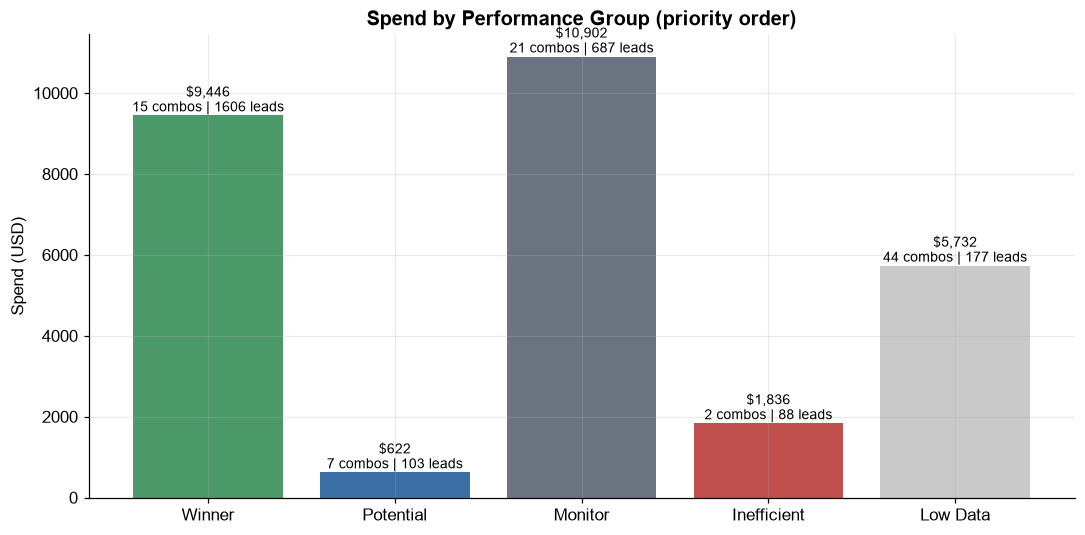

In [21]:

# 优化优先级图：按性能分类汇总 Spend（业务优先级顺序，非字母顺序）
perf_spend = (decision.groupby("Performance")
              .agg(Spend=("Spend", "sum"), Leads=("Leads", "sum"), Combos=("Performance", "size"))
              .reindex(["Winner", "Potential", "Monitor", "Inefficient", "Low Data"])
              .reset_index())

colors = {"Winner": C_LEADS, "Potential": C_SPEND, "Monitor": C_NEUT,
          "Inefficient": C_CPL, "Low Data": "#c9c9c9"}
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(perf_spend["Performance"], perf_spend["Spend"],
              color=[colors[p] for p in perf_spend["Performance"]])
ax.set_ylabel("Spend (USD)")
ax.set_title("Spend by Performance Group (priority order)")
for b, (_, r) in zip(bars, perf_spend.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(),
            f"${r['Spend']:,.0f}\n{int(r['Combos'])} combos | {int(r['Leads'])} leads",
            ha="center", va="bottom", fontsize=9)
fig.tight_layout()
plt.show()



### 9.4 结果观察

- 在 89 个"国家 x 产品"组合中，44 个因 Leads 不足 10 个被归为 **Low Data**，说明大部分组合的样本量都偏小。
- **Winner（15 个）：** 兼具规模与低成本，如 US-RCM01、PL-RM21、AR-RLM01 等。
- **Potential（7 个）：** CPL 达标但规模偏小，如 FR4000-GB、FRX-FR 等，需继续观察能否放大。
- **Inefficient（2 个）：** AU-RM21（60 Leads，CPL 约 $20.35）与 AU-Golf（28 Leads，CPL 约 $21.96）。
- **漏斗标记：** 在 Leads >= 10 的 45 个组合中，主要问题是 `CPL above target`（23 个），其次是 `High CPC`（9 个）、`Low Link CTR`（8 个）和 `Low Click-to-Lead`（6 个）。29 个组合至少带有一个标记，其中 16 个只有单一问题，13 个同时存在两个及以上问题（例如 Portugal-RLM02 同时出现 Low Link CTR、Low Click-to-Lead 与 CPL above target）。这说明用**多个标记**比给每个组合贴唯一标签更能反映真实情况。

### 9.5 业务含义与局限

该框架把"Cpl 达标但规模小"与"Cpl 高但已有规模"区分开，避免把低样本误判为 Winner。但所有阈值都是示例参数：

- 没有销售跟进、线索质量、Demo 与成交数据，**不能**说某组合"已经盈利"或"应直接加预算"；
- 行动建议应表述为"优先测试""继续观察""排查转化问题"等**待验证方向**；
- 若要据此调整预算，还需要：目标 CPL、线索质量评分、销售跟进结果、以及各市场的可扩展容量（受众规模/竞争度）。

**逻辑自检（复核结论）：**

- `Leads < MIN_LEADS` 的组合一律先归为 `Low Data`，不进入 Winner/Potential/Inefficient 判定，行动建议统一为"补齐数据"，避免小样本被误判；
- 分类同时使用 CPL 与 Leads（`Winner` 要求 CPL 达标且 Leads 达标；`Potential` 为 CPL 达标但规模不足；`Inefficient` 为高 CPL 且已具备规模），不存在只凭单一指标下结论；
- 行动建议与漏斗标记保持一致：带有 `Low Click-to-Lead` 或 `High CPC` 的组合会进入"排查转化问题"；
- 若一个 `Winner` 同时带有漏斗标记（如 AR-RLM01 带 `Low Link CTR`），表中会保留该标记，"优先测试放量"应理解为**先小步测试、并同时验证该标记指出的问题**，而不是无条件加预算；
- 以上规则均为**启发式示例**，阈值未经统计检验，不构成确定性业务结论。



## 十、Reach 与 Frequency 口径检查

### 10.1 分析目的

明确 `覆盖人数`（Reach）与 `频次`（Frequency）在本数据集中的口径，避免误用。

### 10.2 关键说明

- 报表的每一行是 **(Campaign x 国家/地区 x 周)**，`覆盖人数` 只在**该行内**去重；
- 把多行 `覆盖人数` 相加（无论是跨周、跨国还是跨 Campaign）都会把同一用户重复计入，因此**不是**真正的去重覆盖人数；
- `频次` 是行级平均展示频次（= 该行展示次数 / 该行覆盖人数），**不能**跨行/跨周相加；真正的周期或周频次需要先去重覆盖，本数据集无法提供；
- 结论：Reach / Frequency 只能在同一行内解读，任何更高层级的汇总都只能作为近似，且会**高估**真实覆盖。


In [22]:

# =========================================================
# 10. Reach / Frequency 口径演示
# =========================================================
# (1) 行级频次：这是口径上唯一准确可用的频次
row_freq = df_analysis[(df_analysis["展示次数"] > 0) & (df_analysis["覆盖人数"] > 0)].copy()
row_freq["row_frequency"] = row_freq["展示次数"] / row_freq["覆盖人数"]
print("行级频率统计（行粒度 = Campaign x 国家 x 周，口径准确）：")
show(row_freq["row_frequency"].describe().to_frame("row_frequency"))

# (2) 若按周简单相加（示意错误做法）：同一用户会被多个 Campaign/国家重复计入
reach_weekly = (df_analysis
                .groupby("week_start")
                .agg(Impressions=("展示次数", "sum"), Reach_sum=("覆盖人数", "sum"))
                .reset_index())
reach_weekly["week_label"] = reach_weekly["week_start"].dt.strftime("%m-%d")
reach_weekly["freq_if_summed"] = reach_weekly["Impressions"] / reach_weekly["Reach_sum"]
show(reach_weekly[["week_label", "Impressions", "Reach_sum", "freq_if_summed"]]
     .rename(columns={"week_label": "周 (开始)", "Reach_sum": "覆盖人数直接相加 (非去重)",
                      "freq_if_summed": "近似频次 = 展示/相加覆盖"}).round(2))

print("各行覆盖人数直接相加：", fmt_int(df_analysis["覆盖人数"].sum()), "（跨行重复计入，非去重覆盖）")
print("各周覆盖人数再相加：", fmt_int(reach_weekly["Reach_sum"].sum()), "（跨周重复计入，非周期去重覆盖）")
print("\n结论：原始数据只提供行级 Reach / Frequency；把它们相加会高估覆盖。")
print("因此本项目不给出周期级或市场级的去重覆盖与整体频次，仅展示行级频率分布与近似值。")


行级频率统计（行粒度 = Campaign x 国家 x 周，口径准确）：
各行覆盖人数直接相加： 1,822,835 （跨行重复计入，非去重覆盖）
各周覆盖人数再相加： 1,822,835 （跨周重复计入，非周期去重覆盖）

结论：原始数据只提供行级 Reach / Frequency；把它们相加会高估覆盖。
因此本项目不给出周期级或市场级的去重覆盖与整体频次，仅展示行级频率分布与近似值。


,row_frequency
count,468.000000
mean,1.508634
std,0.313096
min,1.000000
25%,1.273943
50%,1.457249
75%,1.679100
max,3.048692


,周 (开始),Impressions,覆盖人数直接相加 (非去重),近似频次 = 展示/相加覆盖
0,05-01,353959,216565,1.63
1,05-08,335789,204895,1.64
2,05-15,462201,271979,1.70
3,05-22,414091,249514,1.66
4,05-29,415358,269737,1.54
5,06-05,319292,196905,1.62
6,06-12,268540,152404,1.76
7,06-19,222555,132101,1.68
8,06-26,77300,46975,1.65
9,07-03,37481,21788,1.72



### 10.3 结果观察与局限

各行覆盖人数直接相加约为 182 万，但该数字既不等于周期去重覆盖，也不等于周去重覆盖——同一用户可能被不同 Campaign、不同国家、不同周重复计入。行级频次（展示次数 / 覆盖人数）在本数据中位数约 1.46、最大值约 3.05，可视为单行内的真实平均曝光次数；而把行级 Reach 相加后再估算的"近似频次"（约 1.5–2.1）会因覆盖被高估而失真，只能作为示意，不能作为结论。项目不对周期级或市场级 Reach / Frequency 下结论。



## 十一、分析局限与下一步行动

### 11.1 数据与口径局限

1. **缺少后端业务数据：** 只有广告投放指标，缺少线索质量、销售跟进、Demo、成交与收入数据，无法计算 ROAS/ROI，也不能判断某国家或 Campaign "是否盈利"。
2. **样本量差异大：** 部分国家/组合 Leads 很少（44 个组合 Lead 不足 10 个），其 CPL 波动大，结论需谨慎。
3. **Reach/Frequency 口径：** 仅有分周数据，无法还原周期级去重覆盖与整体频次。
4. **报告周期端点：** 相邻周报的结束日期与下一份的开始日期相同，需留意 Meta 取数是否含端点；本项目按周独立统计，不做跨周累加去重。
5. **阈值为示例参数：** Winner/Potential/Inefficient 与漏斗诊断中使用的阈值均为可调整的示例值，不是行业标准，也未经过统计验证。
6. **报表为历史快照：** 数据仅反映 2026-05-01 至 2026-07-17 的投放表现，不代表长期趋势。

### 11.2 下一步行动建议（均为待验证方向）

1. **优先验证低成本大市场：** 对 US、PL 中 CPL 达标的组合（如 US-RCM01、PL-RM21）做线索质量抽样，确认低 CPL 是否对应有效商机。
2. **排查高成本大市场：** 对 AU（CPL 明显高于整体）从素材、受众与落地页三个方向排查，判断问题在"点击效率"还是"点击后转化"。
3. **谨慎对待小规模高性价比：** AR、BR 及部分低花费 Campaign 的低 CPL 需要结合线索质量与可扩展容量再决定是否放量。
4. **补齐漏斗后端数据：** 引入线索质量评分与销售跟进结果，把 CPL 升级为"每有效线索成本"或"每成交成本"。
5. **建立连续监控：** 以周为单位跟踪 CPL、Link CTR、Click-to-Lead Rate，避免只凭单个周期做判断。

### 11.3 交付说明

- 本 Notebook 由原始周报直接合并计算，所有指标口径统一，可逐段运行复现；
- 原始数据文件未被修改，所有清洗与派生字段均在副本 `df_analysis` 上完成；
- 图表统一使用英文标签与统一配色，避免中文字体缺失导致的乱码。
